# Predicting Cook County Single Family Home Prices using Machine Learning

**Hands-on Machine Learning**
**Authors:** Yuming ZHAI · Sakura ADHIKARY · Vida Kayla BENSING

**Contents**
1. Introduction
2. Data Exploration
3. Data Preprocessing
4. Evaluation Protocol and Baseline
5. Ridge Regression
6. Random Forest
7. Gradient Boosting
8. Model Comparison and Joint Analysis
9. Conclusion
10. Contributions

The notebook runs from top to bottom. It expects the original dataset at `data/training_data.parquet`
([download instructions](https://github.com/ccao-data/model-res-avm#getting-data)).

In [1]:
# Setting up all required libraries
import gc
import json
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import Ridge
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

DATA_PATH = "data/training_data.parquet"

## 1. Introduction


This machine learning project aims to predict residential sale prices using property characteristics and location information. We focus on single-family homes in Cook County, USA.

We will compare Ridge Regression, Random Forest, and Gradient Boosting using the same data splits and evaluation metrics: MAE, RMSE, and R².

### Benchmark and State of the Art
We benchmark our models against the Cook County Assessor’s Office approach (`ccao-data/model-res-avm`). The county previously relied on local linear models per township, but later adopted gradient-boosted trees (LightGBM) to better capture non-linear market behaviour, such as diminishing returns on square footage and localised spatial clustering.

We frame the task as supervised regression. The target is the sales price in USD.

## 2. Data Exploration

We first examine the dataset's scope, feature meanings, missing values,
duplicate records, and unusual values to inform our preprocessing decisions.

### 2.1 Study Population and Date Coverage

In [2]:
# Loading the dataset
df = pd.read_parquet(DATA_PATH)
print("Dataset shape:", df.shape)

Dataset shape: (405195, 203)


In [3]:
# Selecting single family home sale records
houses = df.loc[df["meta_modeling_group"] == "SF"].copy()

# Converting sales dates to datetime
houses["meta_sale_date"] = pd.to_datetime(houses["meta_sale_date"])

print("Single-family dataset shape:", houses.shape)
print("Earliest sale date:", houses["meta_sale_date"].min())
print("Latest sale date:", houses["meta_sale_date"].max())

# Count sale records by year
annual_counts = (
    houses["meta_sale_date"]
    .dt.year
    .value_counts()
    .sort_index()
    .rename_axis("sale_year")
    .rename("number_of_sales")
)

display(annual_counts.to_frame())

Single-family dataset shape: (342547, 203)
Earliest sale date: 2017-01-01 00:00:00
Latest sale date: 2025-12-31 00:00:00


,number_of_sales
sale_year,
2017,41218
2018,41683
2019,40188
2020,42326
2021,41971
2022,39791
2023,32546
2024,30762
2025,32062


The single-family subset contains 342,547 sale records and 203 columns, covering January 2017 to December 2025.
Annual transaction counts range from 30,762 to 42,326, with fewer records from 2023 onwards.

Our tentative chronological split would contain:
- Training (2017–2023): 279,723 records
- Validation (2024): 30,762 records
- Testing (2025): 32,062 records

Feature availability at the time of prediction must be checked before finalising this setup.

In [4]:
# Reserve later years; use the tentative training period for detailed EDA
sale_year = houses["meta_sale_date"].dt.year
eda_train = houses.loc[sale_year <= 2023].copy()

# Summarise each column
column_summary = pd.DataFrame({
    "data_type": eda_train.dtypes.astype(str),
    "missing_count": eda_train.isna().sum(),
    "missing_percent": eda_train.isna().mean().mul(100),
    "unique_values": eda_train.nunique(dropna=True)
})

column_summary["missing_percent"] = (
    column_summary["missing_percent"].round(2)
)

print("Columns with missing values:",
      (column_summary["missing_count"] > 0).sum())

print("Columns with no more than one non-missing value:",
      (column_summary["unique_values"] <= 1).sum())

# Display the 20 columns with the highest missing percentages
display(
    column_summary
    .sort_values("missing_percent", ascending=False)
    .head(20)
)

Columns with missing values: 157
Columns with no more than one non-missing value: 5


,data_type,missing_count,missing_percent,unique_values
other_distressed_community_index,float64,279723,100.00,0
sv_review_json,str,279723,100.00,0
meta_tieback_key_pin,str,279138,99.79,515
loc_tax_special_service_area_num,str,272224,97.32,201
sv_outlier_reason3,str,268280,95.91,7
loc_school_unified_district_geoid,str,267259,95.54,5
loc_tax_tif_district_num,str,265855,95.04,205
sv_outlier_reason2,str,229814,82.16,8
loc_chicago_community_area_name,str,187904,67.18,76
loc_ward_num,str,184457,65.94,50


### 2.2 Missing Values and Constant Features

Within the tentative training subset, 157 columns contain missing values, and five columns have at most one distinct non-missing value.

Two columns are entirely missing: `other_distressed_community_index` and `sv_review_json`. These are candidates for exclusion.

Missing values in other columns require interpretation.
Some may indicate that a geographic or property attribute does not apply,
rather than an incomplete record. We will check feature definitions before choosing exclusion, imputation, or an explicit "not applicable" category.

Sale-review and outlier-related fields will be checked for target leakage before they are considered as model inputs.

In [5]:
# Inspect columns with at most one distinct non-missing value
display(
    column_summary.loc[column_summary["unique_values"] <= 1]
)

# Check the target and exact duplicate rows
print("Missing sale prices:",
      eda_train["meta_sale_price"].isna().sum())

print("Exact duplicate rows:",
      eda_train.duplicated().sum())

# Check whether the same property appears in multiple sale records
if "meta_pin" in eda_train.columns:
    print("Missing property IDs:",
          eda_train["meta_pin"].isna().sum())

    property_counts = eda_train["meta_pin"].value_counts()

    print("Distinct property IDs:", property_counts.size)
    print("Properties with multiple records:",
          (property_counts > 1).sum())

,data_type,missing_count,missing_percent,unique_values
meta_modeling_group,str,0,0.0,1
loc_property_state,str,279,0.1,1
char_ncu,float64,2,0.0,1
other_distressed_community_index,float64,279723,100.0,0
sv_review_json,str,279723,100.0,0


Missing sale prices: 0
Exact duplicate rows: 0
Missing property IDs: 0
Distinct property IDs: 229641
Properties with multiple records: 43676


### 2.3 Constant Features and Duplicate Records

The training subset contains no missing sale prices, no missing property IDs, and no exact duplicate rows.

Its 279,723 sale records correspond to 229,641 distinct property IDs. Of these IDs, 43,676 appear more than once. Repeated property IDs may
represent separate sales and will not be removed solely because they repeat.
We will also check property overlap across the chronological splits.

We propose excluding five input columns: `meta_modeling_group`, `loc_property_state`, `char_ncu`, `other_distressed_community_index`, and `sv_review_json`.
These columns are either entirely missing or have only one distinct non-missing value in the training subset.

In [6]:
# Examine the target and basic property characteristics
basic_columns = [
    "meta_sale_price",
    "char_bldg_sf",
    "char_beds",
    "char_yrblt"
]

display(
    eda_train[basic_columns]
    .describe(percentiles=[0.01, 0.25, 0.5, 0.75, 0.99])
    .round(2)
)

,meta_sale_price,char_bldg_sf,char_beds,char_yrblt
count,279723.00,279704.00,279694.00,279718.00
mean,354173.64,1636.28,3.20,1955.84
std,357138.56,824.48,0.84,29.68
min,10001.00,309.00,1.00,1826.00
1%,25000.00,712.00,2.00,1888.00
25%,175000.00,1100.00,3.00,1941.00
50%,270000.00,1371.00,3.00,1957.00
75%,405000.00,1923.00,4.00,1972.00
99%,1750000.00,4597.00,6.00,2018.00
max,16000000.00,17357.00,14.00,2023.00


### 2.4 Numerical Distributions

The median sale price is $270,000, compared with a mean of approximately $354,174, suggesting a right-skewed price distribution.
The middle 50% of sale prices range from $175,000 to $405,000.

The 99th percentile is $1.75 million, while the maximum is $16 million.
Extreme prices and property characteristics require further inspection; they will not be removed solely because they are large.

Building area, bedroom count, and construction year have 19, 29, and 5 missing values, respectively.

In [7]:
# Inspect the ten most expensive sale records
display(
    eda_train.nlargest(10, "meta_sale_price")[
        [
            "meta_pin",
            "meta_sale_date",
            "meta_sale_price",
            "char_bldg_sf",
            "char_beds",
            "char_yrblt"
        ]
    ]
)

# Flag construction years later than the sale year
built_after_sale = (
    eda_train["char_yrblt"]
    > eda_train["meta_sale_date"].dt.year
)

print("Records with construction year later than sale year:",
      built_after_sale.sum())

display(
    eda_train.loc[built_after_sale, [
        "meta_sale_date", "char_yrblt"
    ]].head(10)
)

,meta_pin,meta_sale_date,meta_sale_price,char_bldg_sf,char_beds,char_yrblt
324136,05214120090000,2022-07-08,16000000.0,9958.0,6.0,2014.0
122718,05161060310000,2022-08-15,12750000.0,5362.0,6.0,1904.0
122719,05161060310000,2022-08-15,12750000.0,935.0,3.0,1920.0
158368,05161060440000,2023-07-28,12500000.0,7094.0,5.0,2005.0
278406,05212020010000,2023-08-23,12250000.0,2187.0,3.0,1911.0
278407,05212020010000,2023-08-23,12250000.0,6174.0,6.0,1911.0
17964,05211040020000,2020-07-24,12000000.0,14280.0,6.0,1921.0
17965,05211040020000,2020-07-24,12000000.0,816.0,2.0,1923.0
100996,05172030380000,2018-04-24,12000000.0,9436.0,6.0,2015.0
329830,05212020150000,2022-06-12,12000000.0,7934.0,8.0,2017.0


Records with construction year later than sale year: 0


,meta_sale_date,char_yrblt


### 2.5 Extreme Prices and Multiple Rows per Sale

The ten highest-priced records include cases with the same property ID, sale date, and sale price, but different building characteristics.
These are not exact duplicate rows. Their meaning requires further investigation before deciding whether to retain or consolidate them.

No non-missing construction year is later than its corresponding sale year.
This check alone does not establish that all features were available at the time of sale.

Next, we count groups sharing the same property ID, sale date, and sale price to measure how common the multiple-row pattern is.

In [8]:
# Count rows sharing the same property ID, sale date, and sale price
sale_key = ["meta_pin", "meta_sale_date", "meta_sale_price"]

sale_group_sizes = (
    eda_train.groupby(sale_key, dropna=False)
    .size()
    .rename("row_count")
)

multiple_row_sales = sale_group_sizes[sale_group_sizes > 1]

print("Sale-key groups with multiple rows:", len(multiple_row_sales))
print("Total rows in these groups:", multiple_row_sales.sum())

# Show ten examples
display(
    multiple_row_sales
    .sort_values(ascending=False)
    .head(10)
    .reset_index()
)

Sale-key groups with multiple rows: 987
Total rows in these groups: 3036


,meta_pin,meta_sale_date,meta_sale_price,row_count
0,17293090360000,2017-05-18,398000.0,27
1,17293090360000,2018-06-29,1900000.0,27
2,17293090360000,2018-08-17,386800.0,27
3,07221040290000,2017-06-29,424990.0,26
4,07221040290000,2017-10-31,494580.0,26
5,07221040290000,2017-07-27,436870.0,26
6,07221040290000,2017-11-30,418460.0,26
7,07221040290000,2017-09-15,424750.0,26
8,07221040290000,2017-08-18,426380.0,26
9,17293090540000,2023-03-29,583000.0,24


There are 987 groups sharing the same property ID, sale date, and sale price with multiple rows.
These groups contain 3,036 records, approximately 1.09% of the training subset. The largest group contains 27 rows.

These records require further investigation before a cleaning rule is defined. 
Matching sale identifiers do not necessarily imply identical property characteristics.

In [9]:
# Inspect the largest multiple-row sale group
example = multiple_row_sales.idxmax()

group_mask = (
    (eda_train["meta_pin"] == example[0])
    & (eda_train["meta_sale_date"] == example[1])
    & (eda_train["meta_sale_price"] == example[2])
)

example_rows = eda_train.loc[group_mask]

# Identify columns whose values differ within this group
varying_columns = example_rows.columns[
    example_rows.nunique(dropna=False) > 1
]

print("Number of rows in this group:", len(example_rows))
print("Columns that differ:", varying_columns.tolist())

# Show the first ten rows of the differing columns
display(example_rows[varying_columns].head(10))

Number of rows in this group: 27
Columns that differ: ['meta_card_num', 'char_yrblt', 'char_bldg_sf', 'char_beds', 'char_fbath', 'char_hbath', 'char_type_resd', 'char_gar1_att', 'char_gar1_area', 'char_gar1_cnst', 'char_bsmt', 'char_ext_wall', 'char_bsmt_fin', 'char_roof_cnst', 'char_class']


,meta_card_num,char_yrblt,char_bldg_sf,char_beds,char_fbath,char_hbath,char_type_resd,char_gar1_att,char_gar1_area,char_gar1_cnst,char_bsmt,char_ext_wall,char_bsmt_fin,char_roof_cnst,char_class
193508,24,2008.0,2178.0,3.0,2.0,1.0,3,1,1,3,2,3,3,1,295
193509,20,2005.0,2328.0,4.0,3.0,0.0,2,2,2,1,1,2,1,1,278
193510,16,2005.0,2178.0,3.0,2.0,1.0,3,1,1,3,2,3,3,1,295
193511,5,2005.0,2328.0,4.0,3.0,0.0,2,2,2,1,1,2,1,1,278
193512,8,2005.0,2328.0,4.0,3.0,0.0,2,2,2,1,1,2,1,1,278
193513,7,2005.0,2328.0,4.0,3.0,0.0,2,2,2,1,1,2,1,1,278
193514,22,2008.0,2328.0,4.0,3.0,0.0,2,2,2,1,1,2,1,1,295
193515,6,2005.0,2226.0,4.0,3.0,0.0,2,2,2,1,1,3,3,1,278
193516,10,2005.0,2328.0,4.0,3.0,0.0,2,2,2,1,1,2,1,1,295
193517,1,2005.0,2328.0,4.0,3.0,0.0,2,2,2,1,1,2,1,1,278


### 2.6 Investigating Card-Level Records

In the selected 27-row sale group, card numbers and several property characteristics differ, including building area, bedroom count, and construction year.
These rows are therefore not exact duplicates.

Next, we check the number of distinct card numbers and the number of rows per card within this group. 
This will help clarify the record structure before we define a cleaning rule.

In [10]:
# Count distinct card numbers within the selected sale group
print("Rows in this sale group:", len(example_rows))

print("Missing card numbers:",
      example_rows["meta_card_num"].isna().sum())

print("Distinct card numbers:",
      example_rows["meta_card_num"].nunique())

# Show how many rows belong to each card number
display(
    example_rows["meta_card_num"]
    .value_counts(dropna=False)
    .rename_axis("card_number")
    .to_frame("row_count")
    .sort_index()
)

Rows in this sale group: 27
Missing card numbers: 0
Distinct card numbers: 27


,row_count
card_number,
1,1
10,1
11,1
12,1
13,1
14,1
15,1
16,1
17,1


The inspected sale group contains 27 rows and 27 distinct card numbers, with no missing card numbers. Each card appears once. 
Thus, the multiple rows in this example correspond to distinct cards rather than repeated copies of the same card.

This finding concerns one group; the structure of the remaining multiple-row sale groups still requires checking.

### 2.7 Card Counts Across Sale Groups

We now count distinct cards within each property ID, sale date, and sale price group. 
We also check for missing card numbers and repeated records sharing both the sale key and card number.

These checks will inform how we handle multi-card sales in the project.

In [11]:
# Count distinct cards in every sale group
cards_per_sale = (
    eda_train.groupby(sale_key, dropna=False)["meta_card_num"]
    .nunique()
)

print("Missing card numbers:",
      eda_train["meta_card_num"].isna().sum())

print("Sale groups with one distinct card:",
      (cards_per_sale == 1).sum())

print("Sale groups with multiple distinct cards:",
      (cards_per_sale > 1).sum())

# Check repeated combinations of sale key and card number
print("Repeated sale-key and card combinations:",
      eda_train.duplicated(
          subset=sale_key + ["meta_card_num"]
      ).sum())

Missing card numbers: 2
Sale groups with one distinct card: 276685
Sale groups with multiple distinct cards: 987
Repeated sale-key and card combinations: 0


### 2.8 Proposed Handling of Multi-Card Sales

The training subset contains 987 multi-card sale groups covering 3,036 rows.
No repeated combinations of sale key and card number were found.
Two records have missing card numbers.

For this course project, we propose restricting the modelling population to single-card sale groups with an observed card number. 
This avoids treating a shared sale price as a separate target for each card.

This restriction narrows the scope of the project and should be applied consistently across training, validation, and testing.

In [12]:
# Count rows within each sale group and align counts with original rows
rows_per_sale = (
    eda_train.groupby(sale_key, dropna=False)["meta_pin"]
    .transform("size")
)

# Keep one-row sale groups with a known card number
single_card_mask = (
    (rows_per_sale == 1)
    & eda_train["meta_card_num"].notna()
)

eda_single = eda_train.loc[single_card_mask].copy()

print("Original training rows:", len(eda_train))
print("Retained single-card rows:", len(eda_single))
print("Excluded rows:", len(eda_train) - len(eda_single))

Original training rows: 279723
Retained single-card rows: 276685
Excluded rows: 3038


The proposed restriction retains 276,685 training records and excludes 3,038 records (approximately 1.09%):
3,036 rows from multi-row sale groups and two records with missing card numbers.

Subsequent exploration uses this restricted subset. This filtering clarifies the observation structure but does not guarantee data accuracy.

### 2.9 Numerical Summary of the Restricted Subset

We recompute descriptive statistics after restricting the training data to one-row sale groups with known card numbers.
This ensures that the reported distributions describe the proposed modelling population.

In [13]:
# Recompute numerical statistics for the restricted training subset
display(
    eda_single[basic_columns]
    .describe(percentiles=[0.01, 0.25, 0.5, 0.75, 0.99])
    .round(2)
)

,meta_sale_price,char_bldg_sf,char_beds,char_yrblt
count,276685.00,276672.00,276668.00,276682.00
mean,350713.99,1632.87,3.20,1955.65
std,346024.42,819.34,0.84,29.30
min,10001.00,309.00,1.00,1826.00
1%,25000.00,720.00,2.00,1888.00
25%,175000.00,1100.00,3.00,1941.00
50%,270000.00,1368.00,3.00,1956.00
75%,400000.00,1916.00,4.00,1972.00
99%,1725000.00,4583.00,6.00,2017.00
max,16000000.00,17357.00,14.00,2023.00


### 2.10 Sale Price Distribution

The restricted training subset contains 276,685 records. The median sale price remains $270,000, while the mean is approximately $350,714.
The middle 50% of prices range from $175,000 to $400,000.

The maximum price remains $16 million, substantially above the 99th percentile of $1.725 million.
Restricting the observation structure has not removed all extreme values. 
Building area, bedroom count, and construction year have 13, 17, and 3 missing values, respectively.

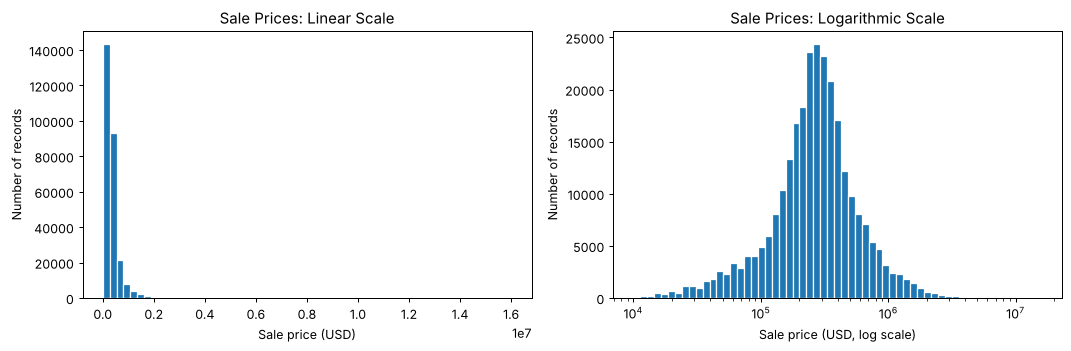

In [14]:
# Use all sale prices in the restricted training subset
prices = eda_single["meta_sale_price"].dropna()

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Equal-width bins on the original dollar scale
axes[0].hist(prices, bins=60, edgecolor="white")
axes[0].set_title("Sale Prices: Linear Scale")
axes[0].set_xlabel("Sale price (USD)")
axes[0].set_ylabel("Number of records")

# Log-spaced bins and a logarithmic horizontal axis
log_bins = np.geomspace(prices.min(), prices.max(), 60)
axes[1].hist(prices, bins=log_bins, edgecolor="white")
axes[1].set_xscale("log")
axes[1].set_title("Sale Prices: Logarithmic Scale")
axes[1].set_xlabel("Sale price (USD, log scale)")
axes[1].set_ylabel("Number of records")

plt.tight_layout()
plt.show()

The linear-scale plot shows that most sales are below $2 million.
Higher-price records remain present, but their bars are barely visible because their counts are small.

The logarithmic view reveals the main concentration of sale prices more clearly.
Together, the plots and summary statistics indicate a right-skewed distribution with a small number of high-price records.

### 2.11 Building Area and Sale Price

We examine the relationship between building area and sale price using a scatter plot of a reproducible random sample from the restricted training subset. 
Both axes use logarithmic scales to make the wide ranges easier to inspect.

Spearman correlation: 0.618


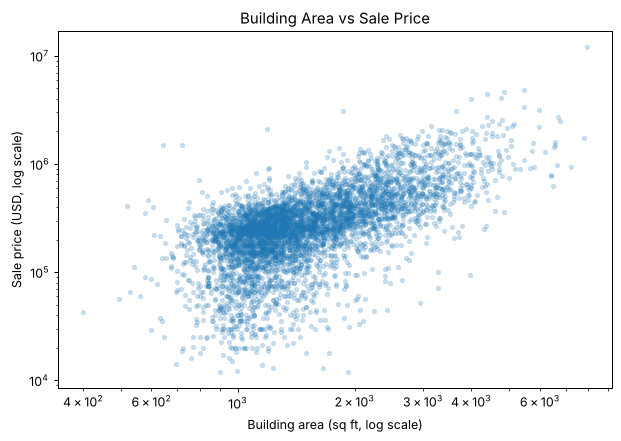

In [15]:
# Select records with observed, positive area and price
area_price = eda_single[
    ["char_bldg_sf", "meta_sale_price"]
].dropna()

area_price = area_price.loc[
    (area_price["char_bldg_sf"] > 0)
    & (area_price["meta_sale_price"] > 0)
]

# Sample records to keep the plot readable
plot_sample = area_price.sample(
    n=min(5000, len(area_price)),
    random_state=42
)

# Plot building area against sale price
plt.figure(figsize=(7, 5))

plt.scatter(
    plot_sample["char_bldg_sf"],
    plot_sample["meta_sale_price"],
    alpha=0.2,
    s=10
)

plt.xscale("log")
plt.yscale("log")
plt.xlabel("Building area (sq ft, log scale)")
plt.ylabel("Sale price (USD, log scale)")
plt.title("Building Area vs Sale Price")
plt.tight_layout()
plt.show()

area_price_correlation = area_price.corr(method="spearman").loc[
    "char_bldg_sf", "meta_sale_price"
]

print("Spearman correlation:", round(area_price_correlation, 3))

The scatter plot shows an overall positive association between building area and sale price, consistent with a Spearman correlation of 0.618.

However, prices vary substantially among homes of similar size.
Building area is therefore a useful candidate predictor, but additional property and location features are needed to capture price differences.

### 2.12 Feature Review

We review the available fields before selecting model inputs.
Each candidate feature will be checked for its meaning, data quality, and availability at prediction time. 
Identifiers and information derived from the target will be excluded from the model inputs.

In [16]:
# List all available fields for review
for column in eda_single.columns:
    print(column)

meta_sale_price
meta_sale_date
meta_sale_document_num
meta_sale_deed_type
meta_sale_seller_name
meta_sale_buyer_name
meta_sale_count_past_n_years
meta_pin
meta_pin10
meta_year
meta_class
meta_modeling_group
meta_triad_name
meta_triad_code
meta_township_name
meta_township_code
meta_nbhd_code
meta_tax_code
meta_tieback_key_pin
meta_tieback_proration_rate
ind_pin_is_prorated
meta_card_num
ind_pin_is_multicard
meta_pin_num_cards
ind_pin_is_multiland
meta_pin_num_landlines
hie_num_active
meta_cdu
meta_mailed_bldg
meta_mailed_land
meta_mailed_tot
meta_certified_bldg
meta_certified_land
meta_certified_tot
meta_board_bldg
meta_board_land
meta_board_tot
meta_1yr_pri_board_bldg
meta_1yr_pri_board_land
meta_1yr_pri_board_tot
meta_2yr_pri_board_bldg
meta_2yr_pri_board_land
meta_2yr_pri_board_tot
loc_property_address
loc_property_city
loc_property_state
loc_property_zip
loc_longitude
loc_latitude
loc_x_3435
loc_y_3435
char_yrblt
char_bldg_sf
char_land_sf
char_beds
char_rooms
char_fbath
char_hbath
c

Candidate inputs include property characteristics, geographic information, and contextual features, subject to checking their definitions and timing.
Identifiers, sale-review outputs, and existing assessed values are excluded from the initial input set.

The earlier filter retained one-row sale groups. 
We now inspect the explicit card-count fields, because one observed row does not necessarily establish that a property has only one card.

In [17]:
# Inspect explicit card information in the retained subset
display(
    eda_single[
        ["ind_pin_is_multicard", "meta_pin_num_cards"]
    ].value_counts(dropna=False).to_frame("number_of_records")
)

,,number_of_records
ind_pin_is_multicard,meta_pin_num_cards,
False,1.0,276685


All 276,685 retained records have `ind_pin_is_multicard = False` and `meta_pin_num_cards = 1`. 
The explicit card fields therefore confirm the single-card status of the retained training subset.

### 2.13 Property Feature Candidates

We inspect the data types, missingness, and distinct-value counts of property-characteristic fields in the restricted training subset.
These fields are candidates, not yet the final model inputs.

In [18]:
# Identify property-characteristic columns
property_columns = [
    column for column in eda_single.columns
    if column.startswith("char_")
]

# Summarise candidate property features
property_summary = pd.DataFrame({
    "data_type": eda_single[property_columns].dtypes.astype(str),
    "missing_percent": (
        eda_single[property_columns].isna().mean() * 100
    ).round(2),
    "unique_values": eda_single[property_columns].nunique()
})

display(property_summary)

,data_type,missing_percent,unique_values
char_yrblt,float64,0.00,175
char_bldg_sf,float64,0.00,5565
char_land_sf,float64,0.00,20613
char_beds,float64,0.01,13
char_rooms,float64,0.01,27
char_fbath,float64,0.01,10
char_hbath,float64,0.00,8
char_frpl,float64,0.24,10
char_type_resd,str,0.15,6
char_cnst_qlty,str,0.01,3


Most property-characteristic fields have low missingness. Numerical measurements and categorical attributes are retained as candidates.

`char_apts` and `char_ncu` are excluded because each has only one distinct non-missing value in the restricted training subset.
For the initial feature set, we also omit the relatively incomplete `char_tp_dsgn` and `char_tp_plan` fields.

Renovation and percentile-derived fields are deferred pending clarification of their definitions and timing. 
These choices define an initial candidate set rather than establish historical feature availability.

In [19]:
# Define exclusions from the initial property feature candidates
excluded_property_columns = [
    "char_apts",
    "char_ncu",
    "char_tp_dsgn",
    "char_tp_plan",
    "char_recent_renovation",
    "char_land_sf_95_percentile",
    "char_bldg_sf_95_percentile"
]

# Retain the remaining property fields as candidates
property_features = [
    column for column in property_columns
    if column not in excluded_property_columns
]

print("Number of candidate property features:", len(property_features))
print(property_features)

Number of candidate property features: 25
['char_yrblt', 'char_bldg_sf', 'char_land_sf', 'char_beds', 'char_rooms', 'char_fbath', 'char_hbath', 'char_frpl', 'char_type_resd', 'char_cnst_qlty', 'char_attic_fnsh', 'char_gar1_att', 'char_gar1_area', 'char_gar1_size', 'char_gar1_cnst', 'char_attic_type', 'char_bsmt', 'char_ext_wall', 'char_heat', 'char_bsmt_fin', 'char_roof_cnst', 'char_class', 'char_use', 'char_porch', 'char_air']


### 2.14 Location and Contextual Feature Candidates

We inspect geographic, environmental, proximity, and parcel-shape fields.
These may capture price differences between homes with similar physical characteristics. 
Their definitions and temporal availability still require review before final inclusion.

In [20]:
# Identify location, proximity, and parcel-shape fields
context_columns = [
    column for column in eda_single.columns
    if column.startswith(("loc_", "prox_", "shp_"))
]

# Summarise their completeness and variation
context_summary = pd.DataFrame({
    "data_type": eda_single[context_columns].dtypes.astype(str),
    "missing_percent": (
        eda_single[context_columns].isna().mean() * 100
    ).round(2),
    "unique_values": eda_single[context_columns].nunique()
})

# Display all candidate fields, including those normally hidden by pandas
with pd.option_context("display.max_rows", None):
    display(context_summary)

,data_type,missing_percent,unique_values
loc_property_address,str,0.00,228238
loc_property_city,str,0.00,137
loc_property_state,str,0.08,1
loc_property_zip,str,0.35,173
loc_longitude,float64,0.00,240104
loc_latitude,float64,0.00,240106
loc_x_3435,float64,0.00,240099
loc_y_3435,float64,0.00,240107
loc_census_puma_geoid,str,0.00,70
loc_census_tract_geoid,str,0.00,1324


Most location and proximity fields have low missingness.
We retain a candidate set covering geographic location, environmental conditions, accessibility, proximity, and parcel geometry.

The initial set omits raw addresses, the constant state field, an alternative coordinate representation, and the high-cardinality subdivision identifier. 
Selected incomplete fields are also deferred for simplicity; their missingness is not automatically interpreted as an error.

Census-version fields and selected time-sensitive contextual measures require further review.
All retained contextual fields remain provisional until their definitions and timing have been checked.

In [21]:
# Define fields deferred from the initial contextual candidates
excluded_context_columns = [
    "loc_property_address",
    "loc_property_state",
    "loc_x_3435",
    "loc_y_3435",
    "loc_misc_subdivision_id",
    "loc_ward_num",
    "loc_chicago_community_area_name",
    "loc_school_unified_district_geoid",
    "loc_tax_special_service_area_num",
    "loc_tax_tif_district_num",
    "prox_avg_school_rating_in_half_mile",
    "prox_nearest_road_highway_speed_limit",
    "prox_num_foreclosure_per_1000_pin_past_5_years",
    "prox_nearest_new_construction_dist_ft",
    "prox_nearest_vacant_land_dist_ft"
]

# Keep remaining fields, while deferring census-related fields
context_features = [
    column for column in context_columns
    if column not in excluded_context_columns
    and not column.startswith("loc_census_")
]

print("Candidate property features:", len(property_features))
print("Candidate contextual features:", len(context_features))
print("Combined candidate count:",
      len(property_features) + len(context_features))

Candidate property features: 25
Candidate contextual features: 56
Combined candidate count: 81


### 2.15 Temporal Information Check

Our proposed split uses sale dates: 2017–2023 for training, 2024 for validation, and 2025 for testing.

We inspect the other year fields to clarify the timing of property and contextual information.
A chronological sale split alone does not guarantee that every predictor was available at the time of sale.

In [22]:
# Inspect year metadata without changing the candidate feature list
year_columns = [
    "meta_year",
    "year",
    "loc_census_data_year",
    "loc_census_acs5_data_year"
]

for column in year_columns:
    print(f"\n{column}:")
    print(eda_single[column].value_counts(dropna=False).sort_index())


meta_year:
meta_year
2017    40471
2018    41293
2019    39752
2020    41868
2021    41641
2022    39477
2023    32183
Name: count, dtype: int64

year:
year
2017    40471
2018    41293
2019    39752
2020    41868
2021    41641
2022    39477
2023    32183
Name: count, dtype: int64

loc_census_data_year:
loc_census_data_year
2017    40470
2018    41291
2019    39752
2020    41868
2021    41641
2022    39477
2023    32183
NaN         3
Name: count, dtype: int64

loc_census_acs5_data_year:
loc_census_acs5_data_year
2017    40470
2018    41291
2019    39752
2020    41868
2021    41641
2022    39477
2023    32183
NaN         3
Name: count, dtype: int64


The inspected year fields contain values from 2017 to 2023.
Both census-related year fields have three missing values.
We next compare these fields with the sale year record by record.
Matching year labels alone do not establish when the underlying information became available.

In [23]:
# Compare each metadata year with its corresponding sale year
sale_year = eda_single["meta_sale_date"].dt.year

for column in year_columns:
    field_year = pd.to_numeric(eda_single[column], errors="coerce")

    mismatches = (
        field_year.notna()
        & (field_year != sale_year)
    )

    print(
        column,
        "| Missing:", field_year.isna().sum(),
        "| Different from sale year:", mismatches.sum()
    )

meta_year | Missing: 0 | Different from sale year: 0
year | Missing: 0 | Different from sale year: 0
loc_census_data_year | Missing: 3 | Different from sale year: 0
loc_census_acs5_data_year | Missing: 3 | Different from sale year: 0


All non-missing year fields match the corresponding sale year.
`meta_year` and `year` have no missing values; each census-related year field has three missing values.

This confirms consistency of the year labels, but does not establish the publication or update dates of every contextual feature.

### 2.16 Numerical and Categorical Inputs

We separate candidate inputs into numerical and categorical fields.
This distinction guides missing-value handling and model-specific preprocessing. 
Storage types provide an initial classification; coded variables still require a semantic check.

In [24]:
# Combine the two candidate feature lists
candidate_features = property_features + context_features

# Initially classify fields by their stored data types
numeric_features = (
    eda_single[candidate_features]
    .select_dtypes(include="number")
    .columns.tolist()
)

categorical_features = [
    column for column in candidate_features
    if column not in numeric_features
]

print("Numerical candidate count:", len(numeric_features))
print(numeric_features)

print("\nCategorical candidate count:", len(categorical_features))
print(categorical_features)

Numerical candidate count: 54
['char_yrblt', 'char_bldg_sf', 'char_land_sf', 'char_beds', 'char_rooms', 'char_fbath', 'char_hbath', 'char_frpl', 'loc_longitude', 'loc_latitude', 'loc_env_flood_fs_factor', 'loc_env_flood_fs_risk_direction', 'loc_env_airport_noise_dnl', 'loc_access_cmap_walk_nta_score', 'loc_access_cmap_walk_total_score', 'prox_num_pin_in_half_mile', 'prox_num_bus_stop_in_half_mile', 'prox_num_school_in_half_mile', 'prox_num_school_with_rating_in_half_mile', 'prox_airport_dnl_total', 'prox_nearest_bike_trail_dist_ft', 'prox_nearest_cemetery_dist_ft', 'prox_nearest_cta_route_dist_ft', 'prox_nearest_cta_stop_dist_ft', 'prox_nearest_golf_course_dist_ft', 'prox_nearest_grocery_store_dist_ft', 'prox_nearest_hospital_dist_ft', 'prox_lake_michigan_dist_ft', 'prox_nearest_major_road_dist_ft', 'prox_nearest_metra_route_dist_ft', 'prox_nearest_metra_stop_dist_ft', 'prox_nearest_park_dist_ft', 'prox_nearest_railroad_dist_ft', 'prox_nearest_road_arterial_daily_traffic', 'prox_neares

The 81 candidate features consist of 54 numerical fields and 27 categorical fields, based on their storage types.

Numerical inputs include property size, room counts, coordinates, and distances to nearby facilities. 
Categorical inputs include property characteristics, geographic categories, and road surface types.

This classification is provisional: numerical codes may represent categories and should be checked against the data documentation.

### 2.17 Missing Values in Candidate Features

We examine missing values in the selected candidate features using the training-period data only.
This helps us propose imputation rules for the shared preprocessing pipeline.

In [25]:
# Summarise missing values in the candidate features
candidate_missing = pd.DataFrame({
    "missing_count": eda_single[candidate_features].isna().sum(),
    "missing_percent": (
        eda_single[candidate_features].isna().mean() * 100
    )
})

# Display only features with missing values
display(
    candidate_missing
    .loc[candidate_missing["missing_count"] > 0]
    .sort_values("missing_percent", ascending=False)
    .round(2)
)

,missing_count,missing_percent
prox_nearest_road_collector_speed_limit,50469,18.24
char_gar1_cnst,32243,11.65
prox_nearest_road_highway_daily_traffic,29937,10.82
prox_nearest_road_collector_daily_traffic,2487,0.90
loc_property_zip,982,0.35
char_frpl,662,0.24
prox_nearest_road_arterial_daily_traffic,654,0.24
prox_nearest_road_arterial_speed_limit,631,0.23
loc_env_flood_fs_risk_direction,459,0.17
loc_env_flood_fs_factor,459,0.17


### 2.18 Proposed Missing-Value Handling

Of the 81 candidate features, 77 contain at least one missing value.
The highest missing rates are 18.24% for collector-road speed limits, 11.65% for garage construction type, and 10.82% for highway traffic.

We propose median imputation for numerical features and a separate "Missing" category for categorical features. 
Missing values are not automatically interpreted as zero or as the absence of a facility.

Imputation parameters will be fitted on the training set only and then applied unchanged to the validation and test sets.

### 2.19 Property Overlap Across Time Periods

A property may be sold multiple times and appear in different time periods. 
We check whether properties in 2024 and 2025 were also observed in the training period.

This check uses property IDs only, without examining later-period sale prices.
The results are provisional because the final eligibility rules have not yet been applied to the later periods.

In [26]:
# Extract the sale year
sale_year = houses["meta_sale_date"].dt.year

# Collect distinct property IDs for each period
train_ids = set(eda_single["meta_pin"].dropna())

validation_ids = set(
    houses.loc[sale_year == 2024, "meta_pin"].dropna()
)

test_ids = set(
    houses.loc[sale_year == 2025, "meta_pin"].dropna()
)

# Identify properties shared with the training period
validation_overlap = validation_ids & train_ids
test_overlap = test_ids & train_ids

# Summarise the overlap
overlap_summary = pd.DataFrame({
    "period": ["Validation (2024)", "Test (2025)"],
    "distinct_properties": [
        len(validation_ids),
        len(test_ids)
    ],
    "properties_seen_in_training": [
        len(validation_overlap),
        len(test_overlap)
    ]
})

overlap_summary["overlap_percent"] = (
    overlap_summary["properties_seen_in_training"]
    / overlap_summary["distinct_properties"]
    * 100
).round(2)

display(overlap_summary)

,period,distinct_properties,properties_seen_in_training,overlap_percent
0,Validation (2024),29527,8566,29.01
1,Test (2025),30493,8128,26.66


In the preliminary overlap check, 8,566 of the 29,527 distinct properties in 2024 (29.01%) and 8,128 of the 30,493 distinct properties in 2025 (26.66%) also appear in the filtered training data.

This overlap can reflect repeat sales rather than duplicate records.
We retain the chronological split because our task is to predict later sales, including sales of previously observed properties.
Property IDs will not be used as model inputs.

The evaluation therefore does not measure performance exclusively on unseen properties. 
These overlap rates will be recalculated after applying the final eligibility rules to all periods.

### 2.20 EDA Summary and Shared Modelling Protocol

#### Scope and Data Quality
Our task is to predict sale prices of single-card, single-family properties in Cook County.

The 2017–2023 single-family subset contains 279,723 records. After excluding multi-row sale groups and records with missing card numbers, 276,685 records remain. The explicit property indicators confirm that all retained records have one card.

There are no missing target values or exact duplicate rows in the initial training-period subset. These checks do not guarantee that all remaining records are error-free.

#### Main Findings
Sale prices are strongly right-skewed: the median is $270,000, while the mean is approximately, $350,714 in the filtered subset. High prices are retained rather than automatically treated as errors.

Building area has a positive association with sale price (Spearman correlation: 0.618). However, substantial price variation remains, supporting the use of additional property and location features.

#### Shared Input Features
For our initial model comparison, we select 81 input features: 25 property features and 56 contextual features.

After the adjustment in Section 2.21, the shared feature lists contain 53 numerical and 28 categorical inputs.

Property identifiers, the target sale price, sale-validation fields, and assessment-value fields are excluded from model inputs. Historical availability has not been verified for every selected  feature; this limitation is documented in Section 2.24.

#### Shared Preparation and Evaluation
The same eligibility rules are applied to all three periods. The chronological split contains:

- Training (2017–2023): 276,685 records
- Validation (2024): 30,545 records
- Final testing (2025): 31,535 records

Numerical missing values will be filled using training-set medians.
Categorical missing values will receive a separate "Missing" category.
All learned preprocessing will be fitted on training data only.

All three models will use the same eligible records and selected
input features. Model-specific transformations may differ;
Ridge will additionally use numerical standardisation.

Each model will be tuned using the validation set. The test set
will be reserved for evaluation after model choices are fixed.
All models will report MAE, RMSE and R² on the original sale-price scale.

After final eligibility filtering, 29.09% of distinct validation
properties and 26.76% of distinct test properties were previously
observed in training. The chronological evaluation therefore
includes both previously observed and unseen properties.
Property IDs will not be used as model inputs.

### 2.21 Review of a Potentially Coded Feature

The flood-risk direction field is stored numerically, but it may represent categories rather than a continuous measurement.

We inspect its observed values before confirming its treatment.
The meanings of the codes must be checked against the data documentation.

In [27]:
# Inspect the values and their frequencies
display(
    eda_single["loc_env_flood_fs_risk_direction"]
    .value_counts(dropna=False)
    .rename_axis("stored_value")
    .to_frame("number_of_records")
)

,number_of_records
stored_value,
0.0,238843
1.0,36269
-1.0,1114
NaN,459


The field contains three observed codes (-1, 0 and 1), with 459 missing values. The meanings of these codes remain unverified.

For the provisional preprocessing plan, we treat this field as categorical to avoid imposing a fixed numerical relationship between the codes. 
This choice may be revised after documentation review.

In [28]:
# Provisionally classify the risk-direction field as categorical
coded_feature = "loc_env_flood_fs_risk_direction"

numeric_features = [
    column for column in numeric_features
    if column != coded_feature
]

if coded_feature not in categorical_features:
    categorical_features.append(coded_feature)

print("Numerical candidate count:", len(numeric_features))
print("Categorical candidate count:", len(categorical_features))

Numerical candidate count: 53
Categorical candidate count: 28


### 2.22 Shared Feature Specification
We consolidate the candidate feature lists into a shared specification.
Each feature is assigned a group, a proposed modelling type, and a missing-value handling strategy.

This specification defines the initial shared input set for all three models.
Any later feature changes must be applied consistently across models.
Temporal-availability limitations are documented in Section 2.24.

In [29]:
# Create one specification row for each candidate feature
feature_spec = pd.DataFrame({
    "feature": candidate_features
})

feature_spec["feature_group"] = feature_spec["feature"].apply(
    lambda column: (
        "Property" if column in property_features else "Contextual"
    )
)

feature_spec["modelling_type"] = feature_spec["feature"].apply(
    lambda column: (
        "Numerical" if column in numeric_features else "Categorical"
    )
)

feature_spec["missing_value_strategy"] = (
    feature_spec["modelling_type"].map({
        "Numerical": "Training-set median",
        "Categorical": "Separate Missing category"
    })
)

display(feature_spec.head(10))

print("Total candidate features:", len(feature_spec))

,feature,feature_group,modelling_type,missing_value_strategy
0,char_yrblt,Property,Numerical,Training-set median
1,char_bldg_sf,Property,Numerical,Training-set median
2,char_land_sf,Property,Numerical,Training-set median
3,char_beds,Property,Numerical,Training-set median
4,char_rooms,Property,Numerical,Training-set median
5,char_fbath,Property,Numerical,Training-set median
6,char_hbath,Property,Numerical,Training-set median
7,char_frpl,Property,Numerical,Training-set median
8,char_type_resd,Property,Categorical,Separate Missing category
9,char_cnst_qlty,Property,Categorical,Separate Missing category


Total candidate features: 81


### 2.23 Consistent Eligibility Rules and Chronological Split

We apply the same eligibility rules to all periods:
one row per sale-key group, a known card number, and property indicators confirming a single card.

We then create training, validation and test subsets by sale year.
Only subset sizes are inspected here; later-period prices are not used for feature selection or tuning.

In [30]:
# Define a sale-key group
sale_key = ["meta_pin", "meta_sale_date", "meta_sale_price"]

# Count the rows in each group across the single-family dataset
rows_per_sale_all = (
    houses.groupby(sale_key, dropna=False)["meta_pin"]
    .transform("size")
)

# Apply the agreed eligibility rules
eligible_mask = (
    (rows_per_sale_all == 1)
    & houses["meta_card_num"].notna()
    & houses["ind_pin_is_multicard"].eq(False)
    & houses["meta_pin_num_cards"].eq(1)
)

eligible_houses = houses.loc[eligible_mask].copy()

# Split eligible records by sale year
eligible_year = eligible_houses["meta_sale_date"].dt.year

train_data = eligible_houses.loc[
    eligible_year.between(2017, 2023)
].copy()

validation_data = eligible_houses.loc[
    eligible_year == 2024
].copy()

test_data = eligible_houses.loc[
    eligible_year == 2025
].copy()

print("Training records:", len(train_data))
print("Validation records:", len(validation_data))
print("Test records:", len(test_data))

# Verify that the training subset matches the earlier EDA subset
print(
    "Training rows match earlier EDA:",
    train_data.index.equals(eda_single.index)
)

Training records: 276685
Validation records: 30545
Test records: 31535
Training rows match earlier EDA: True


After applying the same eligibility rules to all periods, the split contains 276,685 training records, 30,545 validation records, and 31,535 test records.

The training subset matches the earlier EDA subset, so the training exploration remains applicable.

We recalculate property-ID overlap using the final eligible subsets.
These percentages describe distinct properties, rather than sale records.

In [31]:
# Collect distinct property IDs from the eligible subsets
train_ids = set(train_data["meta_pin"].dropna())
validation_ids = set(validation_data["meta_pin"].dropna())
test_ids = set(test_data["meta_pin"].dropna())

# Summarise overlap with training properties
final_overlap = pd.DataFrame({
    "period": ["Validation (2024)", "Test (2025)"],
    "distinct_properties": [
        len(validation_ids),
        len(test_ids)
    ],
    "properties_seen_in_training": [
        len(validation_ids & train_ids),
        len(test_ids & train_ids)
    ]
})

final_overlap["overlap_percent"] = (
    final_overlap["properties_seen_in_training"]
    / final_overlap["distinct_properties"]
    * 100
).round(2)

display(final_overlap)

,period,distinct_properties,properties_seen_in_training,overlap_percent
0,Validation (2024),29434,8561,29.09
1,Test (2025),30357,8125,26.76


After final eligibility filtering, 8,561 of the 29,434 distinct validation properties (29.09%) and 8,125 of the 30,357 distinct test properties (26.76%) were previously observed in training.

The chronological evaluation therefore includes both previously observed and unseen properties. 
Multiple sales of the same property are retained when they represent separate eligible sale records.
Property IDs will not be used as model inputs.

### 2.24 Temporal Availability and Limitations

The non-missing year labels checked during EDA match the sale year.
However, matching year labels does not establish that every input was available before the corresponding sale.

The dataset combines property records with contextual information from multiple sources.
We have not verified historical versions or publication dates for all candidate inputs.

Our project therefore compares models on the supplied dataset using a chronological sale-year split.
It should not be interpreted as a fully verified real-time forecasting system.

We exclude identifiers, sale-validation fields and assessment values from the candidate inputs.
Additional temporal uncertainty remains and will be reported as a limitation.

## 3. Data Preprocessing

This section implements the shared data preparation agreed in Section 2 (EDA).
All three models (Ridge, Random Forest, Gradient Boosting) start from **the same eligible records,
the same chronological split and the same 81 imputed inputs**.

| Step | Learned from data? | Fitted on |
|---|---|---|
| Single-family, single-card eligibility filter | No (row rules) | n/a |
| Chronological split 2017–2023 / 2024 / 2025 | No | n/a |
| Type standardisation (codes → string labels) | No | n/a |
| Median imputation (numerical) | **Yes** | **2017–2023 only** |
| `"Missing"` category (categorical) | No (constant) | 2017–2023 only |
| Scaling + one-hot (Ridge) / ordinal codes (trees) | **Yes** | **2017–2023 only**, inside each model's pipeline |

### 3.1 Configuration and Shared Feature Lists

The feature lists below are written out explicitly (rather than derived from storage types)
so that every model gets the same 53 numerical and 28 categorical inputs regardless of
pandas or pyarrow version. We also check them against the lists derived in Section 2.

In [32]:
TARGET = "meta_sale_price"
SALE_KEY = ["meta_pin", "meta_sale_date", "meta_sale_price"]
TRAIN_YEARS = (2017, 2023)
VAL_YEAR = 2024
TEST_YEAR = 2025
MISSING_LABEL = "Missing"

# Non-input columns kept alongside each split for error analysis (Phase 4).
# They are NOT model inputs.
ANALYSIS_COLUMNS = [
    "meta_pin", "meta_sale_date", "meta_township_code",
    "meta_nbhd_code", "meta_triad_name",
]

NUMERIC_FEATURES = [
    "char_yrblt", "char_bldg_sf", "char_land_sf", "char_beds", "char_rooms",
    "char_fbath", "char_hbath", "char_frpl", "loc_longitude", "loc_latitude",
    "loc_env_flood_fs_factor", "loc_env_airport_noise_dnl",
    "loc_access_cmap_walk_nta_score", "loc_access_cmap_walk_total_score",
    "prox_num_pin_in_half_mile", "prox_num_bus_stop_in_half_mile",
    "prox_num_school_in_half_mile", "prox_num_school_with_rating_in_half_mile",
    "prox_airport_dnl_total", "prox_nearest_bike_trail_dist_ft",
    "prox_nearest_cemetery_dist_ft", "prox_nearest_cta_route_dist_ft",
    "prox_nearest_cta_stop_dist_ft", "prox_nearest_golf_course_dist_ft",
    "prox_nearest_grocery_store_dist_ft", "prox_nearest_hospital_dist_ft",
    "prox_lake_michigan_dist_ft", "prox_nearest_major_road_dist_ft",
    "prox_nearest_metra_route_dist_ft", "prox_nearest_metra_stop_dist_ft",
    "prox_nearest_park_dist_ft", "prox_nearest_railroad_dist_ft",
    "prox_nearest_road_arterial_daily_traffic", "prox_nearest_road_arterial_dist_ft",
    "prox_nearest_road_arterial_lanes", "prox_nearest_road_arterial_speed_limit",
    "prox_nearest_road_collector_daily_traffic", "prox_nearest_road_collector_dist_ft",
    "prox_nearest_road_collector_lanes", "prox_nearest_road_collector_speed_limit",
    "prox_nearest_road_highway_daily_traffic", "prox_nearest_road_highway_dist_ft",
    "prox_nearest_road_highway_lanes", "prox_nearest_secondary_road_dist_ft",
    "prox_nearest_stadium_dist_ft", "prox_nearest_university_dist_ft",
    "prox_nearest_water_dist_ft", "shp_parcel_centroid_dist_ft_sd",
    "shp_parcel_edge_len_ft_sd", "shp_parcel_interior_angle_sd",
    "shp_parcel_mrr_area_ratio", "shp_parcel_mrr_side_ratio",
    "shp_parcel_num_vertices",
]

CATEGORICAL_FEATURES = [
    "char_type_resd", "char_cnst_qlty", "char_attic_fnsh", "char_gar1_att",
    "char_gar1_area", "char_gar1_size", "char_gar1_cnst", "char_attic_type",
    "char_bsmt", "char_ext_wall", "char_heat", "char_bsmt_fin", "char_roof_cnst",
    "char_class", "char_use", "char_porch", "char_air", "loc_property_city",
    "loc_property_zip", "loc_tax_municipality_name",
    "loc_school_elementary_district_geoid", "loc_school_secondary_district_geoid",
    "loc_env_flood_fema_sfha", "loc_env_flood_fs_risk_direction",
    "loc_env_ohare_noise_contour_no_buffer_bool",
    "prox_nearest_road_arterial_surface_type",
    "prox_nearest_road_collector_surface_type",
    "prox_nearest_road_highway_surface_type",
]

FEATURES = NUMERIC_FEATURES + CATEGORICAL_FEATURES
assert len(NUMERIC_FEATURES) == 53 and len(CATEGORICAL_FEATURES) == 28

# The explicit lists must match the candidate lists derived during exploration (Sections 2.16–2.21)
assert set(NUMERIC_FEATURES) == set(numeric_features)
assert set(CATEGORICAL_FEATURES) == set(categorical_features)
print("Feature lists match the EDA:", len(NUMERIC_FEATURES), "numerical +", len(CATEGORICAL_FEATURES), "categorical")

Feature lists match the EDA: 53 numerical + 28 categorical


### 3.2 Eligibility Rules and Chronological Split

We re-apply the Section 2.23 rules to the full single-family dataset: one row per
(property ID, sale date, sale price) group, a known card number, and indicators confirming a single card.
These are row-level rules and learn nothing from the data, so applying them before splitting
does not leak information across periods.

In [33]:
def select_eligible_sales(df: pd.DataFrame) -> pd.DataFrame:
    """Apply the EDA Section 2.23 eligibility rules to the raw dataset."""
    houses = df.loc[df["meta_modeling_group"] == "SF"].copy()
    houses["meta_sale_date"] = pd.to_datetime(houses["meta_sale_date"])
    rows_per_sale = (
        houses.groupby(SALE_KEY, dropna=False)["meta_pin"].transform("size")
    )
    eligible = (
        (rows_per_sale == 1)
        & houses["meta_card_num"].notna()
        & houses["ind_pin_is_multicard"].eq(False)
        & houses["meta_pin_num_cards"].eq(1)
    )
    return houses.loc[eligible].copy()


def chronological_split(eligible: pd.DataFrame):
    """Return (train, validation, test) DataFrames split by sale year."""
    year = eligible["meta_sale_date"].dt.year
    train = eligible.loc[year.between(*TRAIN_YEARS)].copy()
    val = eligible.loc[year == VAL_YEAR].copy()
    test = eligible.loc[year == TEST_YEAR].copy()
    return train, val, test

In [34]:
eligible = select_eligible_sales(df)
train_df, val_df, test_df = chronological_split(eligible)

split_sizes = pd.DataFrame({
    "split": ["Training (2017–2023)", "Validation (2024)", "Test (2025)"],
    "records": [len(train_df), len(val_df), len(test_df)],
    "first_sale": [d["meta_sale_date"].min().date() for d in (train_df, val_df, test_df)],
    "last_sale": [d["meta_sale_date"].max().date() for d in (train_df, val_df, test_df)],
})
display(split_sizes)

# Must match the EDA split (Section 2.23) exactly
assert (len(train_df), len(val_df), len(test_df)) == (276_685, 30_545, 31_535)
assert train_df.index.equals(train_data.index) and test_df.index.equals(test_data.index)
print("Split sizes and records match the EDA.")

# Keep only the columns used from here on and free memory held by the exploration objects
keep = FEATURES + [TARGET] + ANALYSIS_COLUMNS
train_df, val_df, test_df = (d[keep].copy() for d in (train_df, val_df, test_df))
del df, houses, eda_train, eda_single, eligible_houses, train_data, validation_data, test_data, eligible
gc.collect();

,split,records,first_sale,last_sale
0,Training (2017–2023),276685,2017-01-01,2023-12-31
1,Validation (2024),30545,2024-01-01,2024-12-31
2,Test (2025),31535,2025-01-01,2025-12-31


Split sizes and records match the EDA.


1394

The split reproduces the EDA exactly: 276,685 training, 30,545 validation and 31,535 test records.

### 3.3 Type Standardisation

Categorical inputs are stored in several ways (pandas categories, Python booleans, and
the numerically stored flood-risk direction code). We convert all of them to plain string labels
so that every encoder treats them identically. For example, the flood-risk code `-1.0` becomes `"-1"`
and boolean flags become `"True"`/`"False"`. Missing values are kept as missing at this stage.

In [35]:
def _code_to_label(value):
    """Turn a stored code into a clean string label; keep missing as NaN."""
    if value is None or (isinstance(value, float) and np.isnan(value)):
        return np.nan
    if isinstance(value, (bool, np.bool_)):
        return str(bool(value))
    if isinstance(value, (float, np.floating)) and float(value).is_integer():
        return str(int(value))          # e.g. -1.0 -> "-1"
    return str(value)


def standardise_types(split: pd.DataFrame) -> pd.DataFrame:
    """Select the 81 inputs; numeric -> float64, categorical -> str labels."""
    X = split[FEATURES].copy()
    X[NUMERIC_FEATURES] = X[NUMERIC_FEATURES].apply(pd.to_numeric, errors="coerce").astype("float64")
    for col in CATEGORICAL_FEATURES:
        X[col] = X[col].astype(object).map(_code_to_label).astype(object)
    return X

In [36]:
X_train_raw = standardise_types(train_df)
X_val_raw = standardise_types(val_df)
X_test_raw = standardise_types(test_df)

y_train = train_df[TARGET].astype("float64")
y_val = val_df[TARGET].astype("float64")
y_test = test_df[TARGET].astype("float64")

print("Input matrix shapes:", X_train_raw.shape, X_val_raw.shape, X_test_raw.shape)
print("Missing target values:", y_train.isna().sum(), y_val.isna().sum(), y_test.isna().sum())

display(
    X_train_raw[["loc_env_flood_fs_risk_direction", "loc_env_flood_fema_sfha", "char_air"]]
    .apply(lambda s: s.value_counts(dropna=False).to_dict())
    .to_frame("training value counts")
)

Input matrix shapes: (276685, 81) (30545, 81) (31535, 81)
Missing target values: 0 0 0


,training value counts
loc_env_flood_fs_risk_direction,"{'0': 238843, '1': 36269, '-1': 1114, nan: 459}"
loc_env_flood_fema_sfha,"{'False': 273467, 'True': 3097, nan: 121}"
char_air,"{'1': 153209, '2': 123463, nan: 13}"


### 3.4 Missing-Value Imputation (Fitted on Training Data Only)

As agreed in Section 2.18, numerical gaps are filled with the **training-set median** and categorical gaps
with a separate `"Missing"` label. The imputer is fitted on the 2017–2023 inputs only;
the validation and test sets are transformed with those same training medians.

In [37]:
def make_shared_imputer() -> ColumnTransformer:
    """Median for numeric, constant 'Missing' for categorical."""
    imputer = ColumnTransformer(
        transformers=[
            ("num", SimpleImputer(strategy="median"), NUMERIC_FEATURES),
            ("cat", SimpleImputer(strategy="constant", fill_value=MISSING_LABEL,
                                  missing_values=np.nan), CATEGORICAL_FEATURES),
        ],
        verbose_feature_names_out=False,
    )
    return imputer.set_output(transform="pandas")


def apply_imputer(imputer, X: pd.DataFrame) -> pd.DataFrame:
    out = imputer.transform(X)
    out[NUMERIC_FEATURES] = out[NUMERIC_FEATURES].astype("float64")
    out[CATEGORICAL_FEATURES] = out[CATEGORICAL_FEATURES].astype(str)
    return out[FEATURES]

In [38]:
imputer = make_shared_imputer()
imputer.fit(X_train_raw)          # learns medians from 2017–2023 only

X_train = apply_imputer(imputer, X_train_raw)
X_val = apply_imputer(imputer, X_val_raw)
X_test = apply_imputer(imputer, X_test_raw)

# Leakage check: the learned medians equal the training medians
learned_medians = pd.Series(
    imputer.named_transformers_["num"].statistics_, index=NUMERIC_FEATURES
)
assert np.allclose(learned_medians, X_train_raw[NUMERIC_FEATURES].median())
print("Imputer fitted on", imputer.named_transformers_["num"].n_features_in_,
      "numerical features using", len(X_train_raw), "training rows.")

missing_before = pd.DataFrame({
    "train": X_train_raw.isna().sum(),
    "validation": X_val_raw.isna().sum(),
    "test": X_test_raw.isna().sum(),
})
missing_before = missing_before.loc[missing_before.sum(axis=1) > 0]
print("Features with at least one missing value before imputation:", len(missing_before))
display(missing_before.sort_values("train", ascending=False).head(10))

print("Missing values after imputation:",
      int(X_train.isna().sum().sum()), int(X_val.isna().sum().sum()), int(X_test.isna().sum().sum()))
display(learned_medians.loc[missing_before.index.intersection(NUMERIC_FEATURES)]
        .head(8).to_frame("training median used"))

Imputer fitted on 53 numerical features using 276685 training rows.
Features with at least one missing value before imputation: 77


,train,validation,test
prox_nearest_road_collector_speed_limit,50469,5765,5900
char_gar1_cnst,32243,3838,3849
prox_nearest_road_highway_daily_traffic,29937,4922,4974
prox_nearest_road_collector_daily_traffic,2487,71,98
loc_property_zip,982,122,111
char_frpl,662,451,488
prox_nearest_road_arterial_daily_traffic,654,60,61
prox_nearest_road_arterial_speed_limit,631,63,54
loc_env_flood_fs_risk_direction,459,332,355
loc_env_flood_fs_factor,459,332,355


Missing values after imputation: 0 0 0


,training median used
char_yrblt,1956.000000
char_bldg_sf,1368.000000
char_land_sf,6000.000000
char_beds,3.000000
char_rooms,6.000000
char_fbath,1.000000
char_frpl,0.000000
loc_longitude,-87.769461


### 3.5 Categories Unseen in Training

Because the split is chronological, some categorical levels may appear in 2024 or 2025 but never in
2017–2023. The encoders in Section 3.6 handle these explicitly (an "infrequent" column for Ridge,
code `-1` for the tree models), so validation and test rows are never dropped.

In [39]:
unseen = []
for col in CATEGORICAL_FEATURES:
    train_levels = set(X_train[col].unique())
    unseen.append({
        "feature": col,
        "train_levels": len(train_levels),
        "val_rows_unseen": int((~X_val[col].isin(train_levels)).sum()),
        "test_rows_unseen": int((~X_test[col].isin(train_levels)).sum()),
    })
unseen = pd.DataFrame(unseen).set_index("feature")
display(unseen.sort_values("train_levels", ascending=False))
print("Features with any unseen level in validation or test:",
      int(((unseen["val_rows_unseen"] + unseen["test_rows_unseen"]) > 0).sum()))

,train_levels,val_rows_unseen,test_rows_unseen
feature,,,
loc_school_elementary_district_geoid,479,0,0
loc_property_zip,174,1,15
loc_property_city,137,86,90
loc_tax_municipality_name,129,0,0
loc_school_secondary_district_geoid,82,0,0
prox_nearest_road_collector_surface_type,19,0,0
prox_nearest_road_arterial_surface_type,17,0,0
char_class,13,0,0
prox_nearest_road_highway_surface_type,13,0,0


Features with any unseen level in validation or test: 2


### 3.6 Model-Specific Encoders

Ridge Regression is sensitive to feature scale and cannot use string categories, so it uses
standardised numerical inputs and one-hot encoded categories (levels with fewer than 20 training
rows are pooled). Random Forest and Gradient Boosting are scale-invariant, so they use the
unscaled numerical inputs and ordinal category codes.

These encoders are placed as the first step of each model's `Pipeline` (or fitted once on `X_train`), so they
learn from 2017–2023 data only. The imputed `X_train`, `X_val` and `X_test` above are the shared inputs for
all three models in Sections 5–7.

In [40]:
def make_ridge_encoder(min_frequency: int = 20) -> ColumnTransformer:
    """Ridge: standardise numerics, one-hot categoricals.

    Levels seen fewer than `min_frequency` times in training are pooled into an
    'infrequent' column; levels unseen in training (2024/2025) map there too.
    """
    return ColumnTransformer(
        transformers=[
            ("num", StandardScaler(), NUMERIC_FEATURES),
            ("cat", OneHotEncoder(handle_unknown="infrequent_if_exist",
                                  min_frequency=min_frequency,
                                  sparse_output=True), CATEGORICAL_FEATURES),
        ]
    )


def make_tree_encoder() -> ColumnTransformer:
    """Random Forest / Gradient Boosting: numerics unscaled, ordinal codes.

    Levels unseen in training are encoded as -1.
    """
    return ColumnTransformer(
        transformers=[
            ("num", "passthrough", NUMERIC_FEATURES),
            ("cat", OrdinalEncoder(handle_unknown="use_encoded_value",
                                   unknown_value=-1, dtype=np.float64),
             CATEGORICAL_FEATURES),
        ]
    )

In [41]:
ridge_encoder = make_ridge_encoder().fit(X_train)
tree_encoder = make_tree_encoder().fit(X_train)

print("Ridge design matrix:", ridge_encoder.transform(X_val).shape,
      "(53 scaled numerical + one-hot columns)")
print("Tree design matrix: ", tree_encoder.transform(X_val).shape)

# Scaling check: training columns have mean 0 and standard deviation 1
scaled_train = ridge_encoder.named_transformers_["num"].transform(X_train[NUMERIC_FEATURES])
print("Max |mean| of scaled training columns:", float(np.abs(scaled_train.mean(axis=0)).max().round(6)))

Ridge design matrix: (30545, 1163) (53 scaled numerical + one-hot columns)
Tree design matrix:  (30545, 81)
Max |mean| of scaled training columns: 0.0


## 4. Evaluation Protocol and Baseline

All models are evaluated with the same function on the original dollar scale:

- **MAE:** average dollar error per property, $\frac{1}{n}\sum |y_i - \hat{y}_i|$, robust to a few very large errors.
- **RMSE:** $\sqrt{\frac{1}{n}\sum (y_i - \hat{y}_i)^2}$, which penalises large errors heavily.
- **R²:** share of price variance explained, $1 - \frac{\sum (y_i - \hat{y}_i)^2}{\sum (y_i - \bar{y})^2}$.

Hyperparameters are selected on the 2024 validation set only. The 2025 test set is used once per model, after
its settings are fixed. The naive baseline predicts the 2017–2023 mean price for every sale.

In [42]:
def evaluate_predictions(name, y_true, y_pred):
    return {
        "model": name,
        "MAE": mean_absolute_error(y_true, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
        "R2": r2_score(y_true, y_pred),
    }

def print_metrics(result):
    print(f"--- {result['model']} ---")
    print(f"MAE:  ${result['MAE']:,.2f}")
    print(f"RMSE: ${result['RMSE']:,.2f}")
    print(f"R²:   {result['R2']:.4f}\n")

train_mean = float(y_train.mean())
baseline_val_result = evaluate_predictions("Mean baseline", y_val, np.full(len(y_val), train_mean))
baseline_test_result = evaluate_predictions("Mean baseline", y_test, np.full(len(y_test), train_mean))

print(f"Training mean price: ${train_mean:,.2f}")
pd.DataFrame([{**baseline_val_result, "split": "Validation 2024"},
              {**baseline_test_result, "split": "Test 2025"}])[["split", "model", "MAE", "RMSE", "R2"]].round(4)

Training mean price: $350,713.99


,split,model,MAE,RMSE,R2
0,Validation 2024,Mean baseline,227823.9716,444016.5549,-0.0463
1,Test 2025,Mean baseline,249127.9742,551842.5913,-0.0518


## 5. Ridge Regression
*Yuming ZHAI*

### 5.1 Model Overview

We use Ridge Regression as a regularised linear reference model
for predicting single-family property sale prices in Cook County.

We use the shared eligible records, 81 input features and
chronological split. Numerical inputs will be standardised,
and categorical inputs will be one-hot encoded.

The regularisation parameter alpha will be selected using the
2024 validation set. The 2025 test set is reserved for final evaluation.

### 5.2 Initial Ridge Model

We first train Ridge Regression with alpha = 1.0.

The pipeline standardises numerical features and one-hot encodes
categorical features before fitting the model. Both the encoder
and the model are fitted on the training data only.

This initial model provides a reference before parameter tuning.

In [43]:
# Combine Ridge-specific preprocessing and the model
ridge_initial = make_pipeline(
    make_ridge_encoder(),
    Ridge(alpha=1.0, solver="lsqr")
)

# Fit preprocessing and the model using training data only
ridge_initial.fit(X_train, y_train)

print("Initial Ridge model trained successfully.")

Initial Ridge model trained successfully.


### 5.3 Validation Evaluation and Parameter Tuning

We evaluate the initial Ridge model and a training-mean baseline
on the 2024 validation set using MAE, RMSE and R².

We then compare alpha values of 0.1, 1, 10, 100 and 1000.
The model with the lowest validation RMSE is selected.
The 2025 test set is not used for parameter selection.

In [44]:
# Fit encoding once on training data and reuse it across alpha values
ridge_encoder = make_ridge_encoder()
X_train_encoded = ridge_encoder.fit_transform(X_train)
X_val_encoded = ridge_encoder.transform(X_val)

print("Encoded training shape:", X_train_encoded.shape)
print("Encoded validation shape:", X_val_encoded.shape)

alphas = [0.1, 1.0, 10.0, 100.0, 1000.0]
ridge_models = {}
ridge_tuning_results = []

for alpha in alphas:
    # Reuse the already-trained initial model for alpha = 1
    if alpha == 1.0:
        model = ridge_initial.named_steps["ridge"]
        predictions = ridge_initial.predict(X_val)
    else:
        model = Ridge(alpha=alpha, solver="lsqr")
        model.fit(X_train_encoded, y_train)
        predictions = model.predict(X_val_encoded)

    ridge_models[alpha] = model

    result = evaluate_predictions(
        f"Ridge alpha={alpha:g}", y_val, predictions
    )
    result["alpha"] = alpha
    ridge_tuning_results.append(result)

    print(
        f"alpha={alpha:g} | "
        f"MAE=${result['MAE']:,.2f} | "
        f"RMSE=${result['RMSE']:,.2f} | "
        f"R²={result['R2']:.4f}"
    )

ridge_tuning_table = (
    pd.DataFrame(ridge_tuning_results)
    .sort_values("RMSE")
    .reset_index(drop=True)
)

best_alpha = float(ridge_tuning_table.loc[0, "alpha"])
best_ridge = ridge_models[best_alpha]

print(f"\nSelected alpha: {best_alpha:g}")

display(ridge_tuning_table.round(4))

validation_comparison = pd.DataFrame([
    baseline_val_result,
    evaluate_predictions(
        "Initial Ridge (alpha=1)",
        y_val,
        ridge_initial.predict(X_val)
    ),
    evaluate_predictions(
        f"Selected Ridge (alpha={best_alpha:g})",
        y_val,
        best_ridge.predict(X_val_encoded)
    )
])

display(validation_comparison.round(4))

Encoded training shape: (276685, 1163)
Encoded validation shape: (30545, 1163)
alpha=0.1 | MAE=$126,845.94 | RMSE=$231,894.07 | R²=0.7146
alpha=1 | MAE=$126,763.12 | RMSE=$231,839.26 | R²=0.7147
alpha=10 | MAE=$126,700.15 | RMSE=$231,933.91 | R²=0.7145
alpha=100 | MAE=$127,107.63 | RMSE=$233,165.44 | R²=0.7115
alpha=1000 | MAE=$130,041.97 | RMSE=$238,850.46 | R²=0.6972

Selected alpha: 1


,model,MAE,RMSE,R2,alpha
0,Ridge alpha=1,126763.1199,231839.2572,0.7147,1.0
1,Ridge alpha=0.1,126845.9362,231894.0658,0.7146,0.1
2,Ridge alpha=10,126700.1494,231933.9138,0.7145,10.0
3,Ridge alpha=100,127107.6334,233165.4352,0.7115,100.0
4,Ridge alpha=1000,130041.9713,238850.4577,0.6972,1000.0


,model,MAE,RMSE,R2
0,Mean baseline,227823.9716,444016.5549,-0.0463
1,Initial Ridge (alpha=1),126763.1199,231839.2572,0.7147
2,Selected Ridge (alpha=1),126763.1199,231839.2572,0.7147


#### 5.3.1 Refine the Alpha Search

The initial search selected alpha = 1, with alpha = 0.1 almost identical.
To check whether even weaker regularisation helps, we also evaluate 0.001 and 0.01 before fixing the model.

Selection is based on validation RMSE. The initial results show
very similar performance for alpha = 0.1 and alpha = 1, so small
differences should not be interpreted as substantial improvements.

In [45]:
for alpha in [0.001, 0.01]:
    model = Ridge(alpha=alpha, solver="lsqr")
    model.fit(X_train_encoded, y_train)
    predictions = model.predict(X_val_encoded)

    ridge_models[alpha] = model

    result = evaluate_predictions(
        f"Ridge alpha={alpha:g}", y_val, predictions
    )
    result["alpha"] = alpha
    ridge_tuning_results.append(result)

ridge_tuning_table = (
    pd.DataFrame(ridge_tuning_results)
    .sort_values("RMSE")
    .reset_index(drop=True)
)

best_alpha = float(ridge_tuning_table.loc[0, "alpha"])
best_ridge = ridge_models[best_alpha]

print(f"Final selected alpha: {best_alpha:g}")
display(ridge_tuning_table.round(4))

Final selected alpha: 1


,model,MAE,RMSE,R2,alpha
0,Ridge alpha=1,126763.1199,231839.2572,0.7147,1.000
1,Ridge alpha=0.001,126847.6823,231893.8907,0.7146,0.001
2,Ridge alpha=0.01,126847.5231,231893.9059,0.7146,0.010
3,Ridge alpha=0.1,126845.9362,231894.0658,0.7146,0.100
4,Ridge alpha=10,126700.1494,231933.9138,0.7145,10.000
5,Ridge alpha=100,127107.6334,233165.4352,0.7115,100.000
6,Ridge alpha=1000,130041.9713,238850.4577,0.6972,1000.000


### 5.4 Final Test Evaluation

After selecting alpha using validation RMSE, we evaluate the
fixed model on the 2025 test set.

The encoder and model remain fitted on the 2017–2023 training data.
We report MAE, RMSE and R² on the original dollar scale and compare
against the training-mean baseline.

Test results will not be used to change the model or its parameters.

In [46]:
# Apply the training-fitted encoder without fitting again
X_test_encoded = ridge_encoder.transform(X_test)

ridge_val_pred = best_ridge.predict(X_val_encoded)
ridge_test_pred = best_ridge.predict(X_test_encoded)

ridge_results = pd.DataFrame([
    {**baseline_val_result, "split": "Validation 2024"},
    {
        **evaluate_predictions(
            "Ridge", y_val, ridge_val_pred
        ),
        "split": "Validation 2024"
    },
    {**baseline_test_result, "split": "Test 2025"},
    {
        **evaluate_predictions(
            "Ridge", y_test, ridge_test_pred
        ),
        "split": "Test 2025"
    }
])[["split", "model", "MAE", "RMSE", "R2"]]

print(f"Fixed alpha: {best_alpha:g}")
display(ridge_results.round(4))

ridge_negative_count = int((ridge_test_pred < 0).sum())
print("Negative test predictions:", ridge_negative_count)
print("Predictions are evaluated without clipping.")

Fixed alpha: 1


,split,model,MAE,RMSE,R2
0,Validation 2024,Mean baseline,227823.9716,444016.5549,-0.0463
1,Validation 2024,Ridge,126763.1199,231839.2572,0.7147
2,Test 2025,Mean baseline,249127.9742,551842.5913,-0.0518
3,Test 2025,Ridge,147295.3561,348119.5846,0.5815


Negative test predictions: 219
Predictions are evaluated without clipping.


### 5.5 Error Analysis

We inspect predicted versus actual prices and signed prediction
errors on the test set. A fixed random sample is used for plotting;
evaluation metrics use all eligible records.

We also summarise errors across fixed actual-price bands.
Positive mean error indicates overprediction; negative mean error
indicates underprediction. These analyses describe the fixed model
and are not used for further tuning.

,records,MAE,mean_error
price_band,,,
Up to $250k,8694,69807.84,-18254.79
$250k–$500k,14348,104101.36,-85605.21
$500k–$1M,6070,177582.42,-143817.27
Above $1M,2423,605232.39,-580386.96


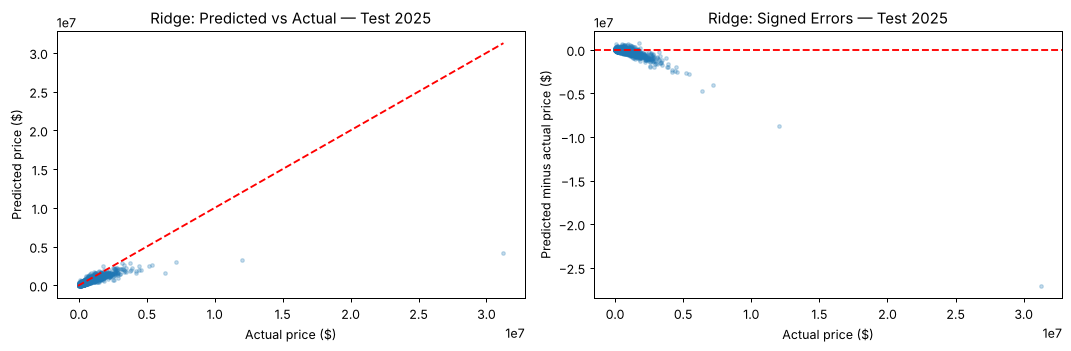

In [47]:
ridge_test_errors = pd.DataFrame({
    "actual_price": np.asarray(y_test),
    "predicted_price": ridge_test_pred
})

ridge_test_errors["error"] = (
    ridge_test_errors["predicted_price"] - ridge_test_errors["actual_price"]
)
ridge_test_errors["absolute_error"] = ridge_test_errors["error"].abs()

ridge_plot_sample = ridge_test_errors.sample(
    n=min(5000, len(ridge_test_errors)),
    random_state=42
)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].scatter(
    ridge_plot_sample["actual_price"],
    ridge_plot_sample["predicted_price"],
    s=8, alpha=0.25
)

lower = min(
    ridge_plot_sample["actual_price"].min(),
    ridge_plot_sample["predicted_price"].min()
)
upper = max(
    ridge_plot_sample["actual_price"].max(),
    ridge_plot_sample["predicted_price"].max()
)

axes[0].plot([lower, upper], [lower, upper], "r--")
axes[0].set_xlabel("Actual price ($)")
axes[0].set_ylabel("Predicted price ($)")
axes[0].set_title("Ridge: Predicted vs Actual — Test 2025")

axes[1].scatter(
    ridge_plot_sample["actual_price"],
    ridge_plot_sample["error"],
    s=8, alpha=0.25
)
axes[1].axhline(0, color="red", linestyle="--")
axes[1].set_xlabel("Actual price ($)")
axes[1].set_ylabel("Predicted minus actual price ($)")
axes[1].set_title("Ridge: Signed Errors — Test 2025")

plt.tight_layout()
plt.show()

ridge_test_errors["price_band"] = pd.cut(
    ridge_test_errors["actual_price"],
    bins=[0, 250_000, 500_000, 1_000_000, np.inf],
    labels=[
        "Up to $250k",
        "$250k–$500k",
        "$500k–$1M",
        "Above $1M"
    ],
    include_lowest=True
)

ridge_band_results = (
    ridge_test_errors.groupby("price_band", observed=True)
    .agg(
        records=("actual_price", "size"),
        MAE=("absolute_error", "mean"),
        mean_error=("error", "mean")
    )
)

display(ridge_band_results.round(2))

### 5.6 Results and Discussion

#### Parameter Selection

Among the seven tested alpha values, alpha = 1 achieved the
lowest validation RMSE and was selected.

However, validation performance was almost identical for alpha
values between 0.001 and 1. The RMSE difference between alpha = 1
and alpha = 0.001 was less than $60. This does not demonstrate a
meaningful advantage for the selected value. Stronger regularisation
at alpha = 100 and 1000 produced worse validation RMSE.

#### Final Performance

| Model | Split | MAE (USD) | RMSE (USD) | R² |
|---|---|---:|---:|---:|
| Mean baseline | Validation 2024 | 227,823.97 | 444,016.55 | -0.0463 |
| Ridge | Validation 2024 | 126,763.12 | 231,839.26 | 0.7147 |
| Mean baseline | Test 2025 | 249,127.97 | 551,842.59 | -0.0518 |
| Ridge | Test 2025 | 147,295.36 | 348,119.58 | 0.5815 |

Ridge reduced test MAE by approximately 40.9% compared with the
training-mean baseline. It therefore learned useful relationships
between the selected features and sale prices.

Performance was weaker on the 2025 test set than on the 2024
validation set. Differences in the price distribution, extreme
sales and relationships between inputs and prices may contribute,
but the current analysis does not establish the cause.

#### Errors Across Price Bands

| Actual price band (USD) | Records | MAE (USD) | Mean signed error (USD) |
|---|---:|---:|---:|
| Up to 250,000 | 8,694 | 69,807.84 | -18,254.79 |
| 250,000–500,000 | 14,348 | 104,101.36 | -85,605.21 |
| 500,000–1,000,000 | 6,070 | 177,582.42 | -143,817.27 |
| Above 1,000,000 | 2,423 | 605,232.39 | -580,386.96 |

Signed error is defined as predicted price minus actual price.
Its negative mean in every band indicates average underprediction.
Absolute dollar errors increase across the price bands, with
particularly large underprediction for properties above $1M.

The plots also show substantial underprediction for some extreme
high-price sales. RMSE is sensitive to these large errors.
These observations do not establish that the expensive sales
are incorrect records.

#### Limitations

The unconstrained linear model produced 219 negative predictions
on the test set, approximately 0.69% of test records. Predictions
were evaluated without clipping. Negative prices are not plausible
and represent a limitation of this model.

Ridge uses an additive linear structure and may miss nonlinear
relationships and interactions. The chronological evaluation also
includes properties previously observed during training.

Historical availability has not been verified for every contextual
input. Results should therefore be interpreted as a retrospective
comparison under the documented dataset assumptions, rather than
evidence of fully verified real-time forecasting performance.

#### Ridge Summary

We trained and tuned Ridge Regression using the shared 81 inputs,
training-only preprocessing and chronological data split.

Ridge substantially improved on the mean-price baseline, but its
test performance was weaker than its validation performance.
Error analysis identified underprediction, especially for expensive
properties, and a small proportion of negative predictions.

Ridge provides a useful linear reference for comparison with
Random Forest and Gradient Boosting. With more time, we would
verify feature availability and investigate nonlinear features
or a log-price target using a new validation protocol. The current
test results will not be used to retune the model.

## 6. Random Forest
*Sakura ADHIKARY*

### 6.1 Model Overview

Random Forest is an ensemble of decision trees trained **in parallel**. Each tree is grown on a
bootstrap sample of the training data, and at every split it only considers a random subset of
the features (`max_features`). The forest prediction is the average of all trees:

$$\hat{f}_{RF}(x) = \frac{1}{B}\sum_{b=1}^{B} T_b(x)$$

A single deep tree has low bias but very high variance: small changes in the data produce a very
different tree. Averaging $B$ trees whose errors are only partly correlated reduces that variance.
If each tree has variance $\sigma^2$ and pairwise correlation $\rho$, the variance of the average is

$$\rho\,\sigma^2 + \frac{1-\rho}{B}\,\sigma^2 .$$

Adding trees shrinks the second term, and subsampling features (smaller `max_features`) lowers
$\rho$, which shrinks the first term. Section 6.4 checks this on our data.

We use the shared eligible records, the 81 shared input features and the chronological split from
Section 3. Tree models do not need scaling, so we use `make_tree_encoder()`
(unscaled numerical inputs, ordinal category codes). Hyperparameters are selected on the 2024
validation set using **validation RMSE**, as for Ridge. The 2025 test set is used once, at the end.

The tree encoder is fitted **once on the 2017–2023 training data** and reused for every experiment, which avoids
re-encoding for each configuration. Validation and test data are only transformed.

In [48]:
# Encoder fitted on training data only
tree_encoder = make_tree_encoder().fit(X_train)
feature_names = NUMERIC_FEATURES + CATEGORICAL_FEATURES

Xtr = tree_encoder.transform(X_train).astype(np.float32)
Xva = tree_encoder.transform(X_val).astype(np.float32)
Xte = tree_encoder.transform(X_test).astype(np.float32)
print("Encoded shapes:", Xtr.shape, Xva.shape, Xte.shape)

Encoded shapes: (276685, 81) (30545, 81) (31535, 81)


### 6.2 Reference: a Single Decision Tree

Before building a forest, we fit one fully grown regression tree. It shows the problem Random Forest
is designed to solve: an unpruned tree almost memorises the training data but generalises much worse.

In [49]:
start = time.time()
single_tree = DecisionTreeRegressor(random_state=42).fit(Xtr, y_train)

# Training fit is measured on a fixed 30,000-row sample to keep this quick
rng = np.random.default_rng(42)
train_sample = rng.choice(len(Xtr), size=30_000, replace=False)

tree_results = pd.DataFrame([
    {**evaluate_predictions("Single tree", y_train.iloc[train_sample],
                            single_tree.predict(Xtr[train_sample])), "split": "Training (sample)"},
    {**evaluate_predictions("Single tree", y_val, single_tree.predict(Xva)), "split": "Validation 2024"},
])[["split", "model", "MAE", "RMSE", "R2"]]

print(f"Depth: {single_tree.get_depth()} | leaves: {single_tree.get_n_leaves():,} | "
      f"fit time: {time.time() - start:.1f}s")
tree_results.round(4)

Depth: 66 | leaves: 257,079 | fit time: 22.3s


,split,model,MAE,RMSE,R2
0,Training (sample),Single tree,3338.8284,17867.5955,0.9975
1,Validation 2024,Single tree,125782.0201,233691.5481,0.7102


### 6.3 Hyperparameter Tuning on the 2024 Validation Set

We tune the three parameters in the project plan in three stages. Other settings stay fixed:
bootstrap sampling, `min_samples_leaf=1`, `random_state=42`.

1. **`max_features`**: the share of features considered at each split. Smaller values make trees
   more different from each other (lower correlation) but each tree slightly weaker.
   Candidates: √p (≈ 0.11), 0.2, 0.33, 0.5 and 1.0 (all features, i.e. plain bagging), with
   `max_depth=20` and 50 trees.
2. **`max_depth`**: candidates 10, 15, 20, 25 and unlimited, using the best `max_features` and 50 trees.
3. **`n_estimators`**: with the two settings fixed, we grow the forest from 10 to 200 trees
   (`warm_start`) and record validation error at each size.

Fifty trees are enough to rank configurations reliably; the number of trees is tuned separately in
stage 3. The selection metric throughout is validation RMSE.

In [50]:
def fit_forest(n_estimators, max_features, max_depth, **kwargs):
    model = RandomForestRegressor(
        n_estimators=n_estimators,
        max_features=max_features,
        max_depth=max_depth,
        min_samples_leaf=1,
        n_jobs=-1,
        random_state=42,
        **kwargs,
    )
    return model.fit(Xtr, y_train)

rf_tuning_rows = []

# Stage 1: max_features
for max_features in ["sqrt", 0.2, 0.33, 0.5, 1.0]:
    start = time.time()
    model = fit_forest(50, max_features, 20)
    result = evaluate_predictions(f"RF max_features={max_features}", y_val, model.predict(Xva))
    result.update(stage="1: max_features", n_estimators=50,
                  max_features=str(max_features), max_depth="20",
                  fit_seconds=round(time.time() - start, 1))
    rf_tuning_rows.append(result)
    print(f"max_features={str(max_features):>5} | RMSE=${result['RMSE']:,.0f} | "
          f"MAE=${result['MAE']:,.0f} | R²={result['R2']:.4f} | {result['fit_seconds']}s")
    del model

stage1 = pd.DataFrame(rf_tuning_rows)
best_max_features_label = stage1.sort_values("RMSE").iloc[0]["max_features"]
best_max_features = best_max_features_label if best_max_features_label == "sqrt" else float(best_max_features_label)
print("\nBest max_features:", best_max_features)

max_features= sqrt | RMSE=$203,727 | MAE=$111,978 | R²=0.7797 | 40.2s
max_features=  0.2 | RMSE=$199,850 | MAE=$110,163 | R²=0.7880 | 67.7s
max_features= 0.33 | RMSE=$197,463 | MAE=$108,869 | R²=0.7931 | 106.4s
max_features=  0.5 | RMSE=$196,430 | MAE=$107,935 | R²=0.7952 | 157.4s
max_features=  1.0 | RMSE=$195,605 | MAE=$107,187 | R²=0.7969 | 306.0s

Best max_features: 1.0


In [51]:
# Stage 2: max_depth (using the best max_features)
for max_depth in [10, 15, 20, 25, None]:
    start = time.time()
    model = fit_forest(50, best_max_features, max_depth)
    result = evaluate_predictions(f"RF max_depth={max_depth}", y_val, model.predict(Xva))
    result.update(stage="2: max_depth", n_estimators=50,
                  max_features=str(best_max_features),
                  max_depth="None" if max_depth is None else str(max_depth),
                  fit_seconds=round(time.time() - start, 1))
    rf_tuning_rows.append(result)
    print(f"max_depth={str(max_depth):>4} | RMSE=${result['RMSE']:,.0f} | "
          f"MAE=${result['MAE']:,.0f} | R²={result['R2']:.4f} | {result['fit_seconds']}s")
    del model

stage2 = pd.DataFrame(rf_tuning_rows).query("stage == '2: max_depth'")
best_depth_label = stage2.sort_values("RMSE").iloc[0]["max_depth"]
best_max_depth = None if best_depth_label == "None" else int(best_depth_label)
print("\nBest max_depth:", best_max_depth)

max_depth=  10 | RMSE=$215,246 | MAE=$120,980 | R²=0.7541 | 185.3s
max_depth=  15 | RMSE=$199,933 | MAE=$111,172 | R²=0.7879 | 252.1s
max_depth=  20 | RMSE=$195,605 | MAE=$107,187 | R²=0.7969 | 310.0s
max_depth=  25 | RMSE=$194,382 | MAE=$106,258 | R²=0.7995 | 318.9s
max_depth=None | RMSE=$195,169 | MAE=$106,165 | R²=0.7978 | 354.1s

Best max_depth: 25


n_estimators= 10 | RMSE=$198,114 | MAE=$108,458 | R²=0.7917
n_estimators= 25 | RMSE=$195,073 | MAE=$106,816 | R²=0.7980
n_estimators= 50 | RMSE=$194,382 | MAE=$106,258 | R²=0.7995
n_estimators=100 | RMSE=$193,894 | MAE=$105,959 | R²=0.8005
n_estimators=150 | RMSE=$193,432 | MAE=$105,920 | R²=0.8014
n_estimators=200 | RMSE=$193,337 | MAE=$105,832 | R²=0.8016

Selected n_estimators: 150


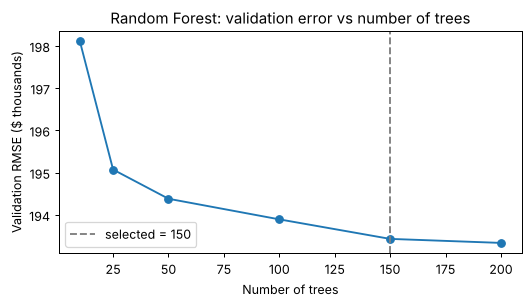

In [52]:
# Stage 3: n_estimators. warm_start adds trees to the same forest, so the first k trees
# are exactly the forest we would get by fitting k trees from scratch with random_state=42.
forest = RandomForestRegressor(
    n_estimators=10, max_features=best_max_features, max_depth=best_max_depth,
    min_samples_leaf=1, n_jobs=-1, random_state=42, warm_start=True,
)

tree_counts = [10, 25, 50, 100, 150, 200]
for n_trees in tree_counts:
    start = time.time()
    forest.set_params(n_estimators=n_trees)
    forest.fit(Xtr, y_train)
    result = evaluate_predictions(f"RF n_estimators={n_trees}", y_val, forest.predict(Xva))
    result.update(stage="3: n_estimators", n_estimators=n_trees,
                  max_features=str(best_max_features), max_depth=str(best_max_depth),
                  fit_seconds=round(time.time() - start, 1))
    rf_tuning_rows.append(result)
    print(f"n_estimators={n_trees:>3} | RMSE=${result['RMSE']:,.0f} | "
          f"MAE=${result['MAE']:,.0f} | R²={result['R2']:.4f}")

stage3 = pd.DataFrame(rf_tuning_rows).query("stage == '3: n_estimators'").reset_index(drop=True)

# Choose the smallest forest within 0.25% of the best validation RMSE:
# beyond that point extra trees cost time and memory for a negligible gain.
best_rmse = stage3["RMSE"].min()
best_n_estimators = int(stage3.loc[stage3["RMSE"] <= best_rmse * 1.0025, "n_estimators"].min())
print("\nSelected n_estimators:", best_n_estimators)

fig, ax = plt.subplots(figsize=(6, 3.5))
ax.plot(stage3["n_estimators"], stage3["RMSE"] / 1000, marker="o")
ax.axvline(best_n_estimators, color="grey", linestyle="--", label=f"selected = {best_n_estimators}")
ax.set_xlabel("Number of trees")
ax.set_ylabel("Validation RMSE ($ thousands)")
ax.set_title("Random Forest: validation error vs number of trees")
ax.legend()
plt.tight_layout()
plt.show()

In [53]:
# Final model: the first best_n_estimators trees of the forest above (fitted on 2017–2023 only)
final_rf = forest
final_rf.estimators_ = final_rf.estimators_[:best_n_estimators]
final_rf.set_params(n_estimators=best_n_estimators, warm_start=False)

rf_best_params = {
    "n_estimators": best_n_estimators,
    "max_depth": best_max_depth,
    "max_features": best_max_features,
}
print("Selected configuration:", rf_best_params)

rf_tuning_table = pd.DataFrame(rf_tuning_rows)[
    ["stage", "n_estimators", "max_features", "max_depth", "MAE", "RMSE", "R2", "fit_seconds"]
]
rf_tuning_table.round(4)

Selected configuration: {'n_estimators': 150, 'max_depth': 25, 'max_features': 1.0}


,stage,n_estimators,max_features,max_depth,MAE,RMSE,R2,fit_seconds
0,1: max_features,50,sqrt,20,111978.1164,203726.7599,0.7797,40.2
1,1: max_features,50,0.2,20,110163.0662,199849.6986,0.7880,67.7
2,1: max_features,50,0.33,20,108868.9345,197462.7371,0.7931,106.4
3,1: max_features,50,0.5,20,107935.3937,196429.6216,0.7952,157.4
4,1: max_features,50,1.0,20,107186.8217,195604.7559,0.7969,306.0
5,2: max_depth,50,1.0,10,120979.9385,215246.2695,0.7541,185.3
6,2: max_depth,50,1.0,15,111171.8899,199932.5265,0.7879,252.1
7,2: max_depth,50,1.0,20,107186.8217,195604.7559,0.7969,310.0
8,2: max_depth,50,1.0,25,106257.8421,194381.9565,0.7995,318.9
9,2: max_depth,50,1.0,None,106164.7286,195168.5959,0.7978,354.1


### 6.4 Does the Forest Reduce Variance?

We check the variance argument from Section 6.1 in three ways, all on the 2024 validation set:

1. **Individual trees vs the forest:** the error of each tree on its own compared with the error of their average.
2. **Disagreement between trees:** how much the trees' predictions differ for the same property.
3. **Overfitting gap:** training vs validation error for the single tree and the forest.

,quantity,value
0,Mean RMSE of an individual tree,237687.1716
1,Best individual tree RMSE,224646.4543
2,Forest RMSE (average of all trees),193431.9080
3,Average pairwise correlation of tree errors,0.6222
4,Average std. of tree predictions per property,91867.0429


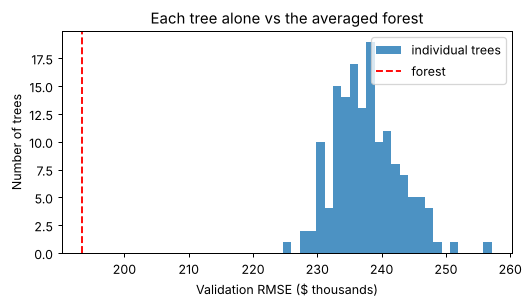

In [54]:
# Predictions of every tree on the validation set: shape (n_trees, n_val)
tree_val_preds = np.vstack([tree.predict(Xva) for tree in final_rf.estimators_])
forest_val_pred = tree_val_preds.mean(axis=0)

individual_rmse = np.sqrt(((tree_val_preds - y_val.to_numpy()) ** 2).mean(axis=1))
forest_rmse = np.sqrt(mean_squared_error(y_val, forest_val_pred))

# Average correlation between the errors of different trees (estimate of rho)
tree_errors = tree_val_preds - y_val.to_numpy()
corr = np.corrcoef(tree_errors)
avg_error_corr = corr[np.triu_indices_from(corr, k=1)].mean()

# Spread of the individual tree predictions for the same property
avg_tree_spread = tree_val_preds.std(axis=0).mean()

variance_summary = pd.DataFrame({
    "quantity": [
        "Mean RMSE of an individual tree",
        "Best individual tree RMSE",
        "Forest RMSE (average of all trees)",
        "Average pairwise correlation of tree errors",
        "Average std. of tree predictions per property",
    ],
    "value": [individual_rmse.mean(), individual_rmse.min(), forest_rmse,
              avg_error_corr, avg_tree_spread],
})
display(variance_summary.round(4))

fig, ax = plt.subplots(figsize=(6, 3.5))
ax.hist(individual_rmse / 1000, bins=25, alpha=0.8, label="individual trees")
ax.axvline(forest_rmse / 1000, color="red", linestyle="--", label="forest")
ax.set_xlabel("Validation RMSE ($ thousands)")
ax.set_ylabel("Number of trees")
ax.set_title("Each tree alone vs the averaged forest")
ax.legend()
plt.tight_layout()
plt.show()

In [55]:
# Overfitting rf_gap: single tree vs forest (training error on the same 30,000-row sample)
rf_gap = pd.DataFrame([
    {**evaluate_predictions("Single tree", y_train.iloc[train_sample], single_tree.predict(Xtr[train_sample])),
     "split": "Training (sample)"},
    {**evaluate_predictions("Single tree", y_val, single_tree.predict(Xva)), "split": "Validation 2024"},
    {**evaluate_predictions("Random Forest", y_train.iloc[train_sample], final_rf.predict(Xtr[train_sample])),
     "split": "Training (sample)"},
    {**evaluate_predictions("Random Forest", y_val, forest_val_pred), "split": "Validation 2024"},
])[["model", "split", "MAE", "RMSE", "R2"]]
rf_gap.round(4)

,model,split,MAE,RMSE,R2
0,Single tree,Training (sample),3338.8284,17867.5955,0.9975
1,Single tree,Validation 2024,125782.0201,233691.5481,0.7102
2,Random Forest,Training (sample),32702.2170,57789.6097,0.9743
3,Random Forest,Validation 2024,105920.1784,193431.9080,0.8014


### 6.5 Final Test Evaluation

The configuration is now fixed. We evaluate it once on the 2025 test set and compare it with the
training-mean baseline. The encoder and the forest remain fitted on 2017–2023 data only.

In [56]:
rf_val_pred = forest_val_pred
rf_test_pred = final_rf.predict(Xte)

rf_results = pd.DataFrame([
    {**baseline_val_result, "split": "Validation 2024"},
    {**evaluate_predictions("Random Forest", y_val, rf_val_pred), "split": "Validation 2024"},
    {**baseline_test_result, "split": "Test 2025"},
    {**evaluate_predictions("Random Forest", y_test, rf_test_pred), "split": "Test 2025"},
])[["split", "model", "MAE", "RMSE", "R2"]]

print("Final configuration:", rf_best_params)
display(rf_results.round(4))
print("Negative test predictions:", int((rf_test_pred < 0).sum()))

Final configuration: {'n_estimators': 150, 'max_depth': 25, 'max_features': 1.0}


,split,model,MAE,RMSE,R2
0,Validation 2024,Mean baseline,227823.9716,444016.5549,-0.0463
1,Validation 2024,Random Forest,105920.1784,193431.9080,0.8014
2,Test 2025,Mean baseline,249127.9742,551842.5913,-0.0518
3,Test 2025,Random Forest,124355.8886,272307.2620,0.7439


Negative test predictions: 0


### 6.6 Error Analysis

We use the same price bands and sign convention as the Ridge section:
signed error = predicted − actual, so a negative mean error means underprediction.

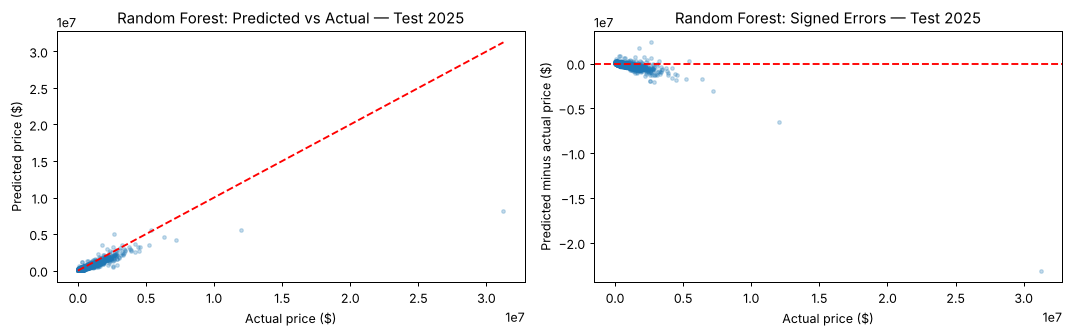

,records,MAE,mean_error
price_band,,,
Up to $250k,8694,55003.62,3237.27
$250k–$500k,14348,83885.76,-72300.42
$500k–$1M,6070,170208.72,-158996.64
Above $1M,2423,497978.41,-468980.40


In [57]:
rf_test_errors = pd.DataFrame({
    "actual_price": y_test.to_numpy(),
    "predicted_price": rf_test_pred,
})
rf_test_errors["error"] = rf_test_errors["predicted_price"] - rf_test_errors["actual_price"]
rf_test_errors["absolute_error"] = rf_test_errors["error"].abs()
rf_test_errors["price_band"] = pd.cut(
    rf_test_errors["actual_price"],
    bins=[0, 250_000, 500_000, 1_000_000, np.inf],
    labels=["Up to $250k", "$250k–$500k", "$500k–$1M", "Above $1M"],
    include_lowest=True,
)

rf_plot_sample = rf_test_errors.sample(n=min(5000, len(rf_test_errors)), random_state=42)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].scatter(rf_plot_sample["actual_price"], rf_plot_sample["predicted_price"], s=8, alpha=0.25)
upper = max(rf_plot_sample["actual_price"].max(), rf_plot_sample["predicted_price"].max())
axes[0].plot([0, upper], [0, upper], "r--")
axes[0].set_xlabel("Actual price ($)")
axes[0].set_ylabel("Predicted price ($)")
axes[0].set_title("Random Forest: Predicted vs Actual — Test 2025")
axes[1].scatter(rf_plot_sample["actual_price"], rf_plot_sample["error"], s=8, alpha=0.25)
axes[1].axhline(0, color="red", linestyle="--")
axes[1].set_xlabel("Actual price ($)")
axes[1].set_ylabel("Predicted minus actual price ($)")
axes[1].set_title("Random Forest: Signed Errors — Test 2025")
plt.tight_layout()
plt.show()

rf_band_results = rf_test_errors.groupby("price_band", observed=True).agg(
    records=("actual_price", "size"),
    MAE=("absolute_error", "mean"),
    mean_error=("error", "mean"),
)
rf_band_results.round(2)

### 6.7 Which Features Does the Forest Use?

Impurity-based importance shows how much each feature reduced squared error across all splits. It is
quick but can favour features with many distinct values, so we also run a **grouped permutation test**
on the validation set: we shuffle all property-characteristic inputs (or all location and contextual
inputs) at once and measure how much validation RMSE increases. Section 8.3 returns to the role of geographic indicators.

In [58]:
rf_importances = pd.Series(final_rf.feature_importances_, index=feature_names).sort_values(ascending=False)
display(rf_importances.head(15).round(4).to_frame("impurity importance"))

rf_groups = {
    "Property characteristics (char_*)": [i for i, f in enumerate(feature_names) if f.startswith("char_")],
    "Location & context (loc_*, prox_*, shp_*)": [i for i, f in enumerate(feature_names) if not f.startswith("char_")],
    "Coordinates only (latitude, longitude)": [feature_names.index("loc_latitude"), feature_names.index("loc_longitude")],
}

perm_rng = np.random.default_rng(0)
perm_rows = []
for group, cols in rf_groups.items():
    increases = []
    for _ in range(3):
        Xperm = Xva.copy()
        rows = perm_rng.permutation(len(Xperm))
        Xperm[:, cols] = Xperm[rows][:, cols]          # shuffle the group's columns together
        rmse = np.sqrt(mean_squared_error(y_val, final_rf.predict(Xperm)))
        increases.append(rmse - forest_rmse)
    perm_rows.append({"feature group": group, "features": len(cols),
                      "RMSE increase when shuffled ($)": np.mean(increases)})
rf_group_importance = pd.DataFrame(perm_rows)
rf_group_importance.round(0)

,impurity importance
char_bldg_sf,0.4397
prox_lake_michigan_dist_ft,0.1969
loc_latitude,0.0825
char_yrblt,0.0267
prox_airport_dnl_total,0.0215
loc_longitude,0.0169
loc_access_cmap_walk_total_score,0.0155
prox_nearest_university_dist_ft,0.0148
char_land_sf,0.0127
loc_access_cmap_walk_nta_score,0.0071


,feature group,features,RMSE increase when shuffled ($)
0,Property characteristics (char_*),25,198772.0
1,"Location & context (loc_*, prox_*, shp_*)",56,212573.0
2,"Coordinates only (latitude, longitude)",2,103701.0


In [59]:
# Free the memory held by the forest and the per-tree predictions before the next model
del forest, final_rf, tree_val_preds, tree_errors, corr, single_tree, Xtr, Xva, Xte
gc.collect();

26646

### 6.8 Results and Discussion

#### Parameter Selection

| Stage | Candidates (validation RMSE, 50 trees unless stated) | Selected |
|---|---|---|
| `max_features` (depth 20) | √p: \$203,727 · 0.2: \$199,850 · 0.33: \$197,463 · 0.5: \$196,430 · 1.0: \$195,605 | **1.0** |
| `max_depth` (all features) | 10: \$215,246 · 15: \$199,933 · 20: \$195,605 · 25: \$194,382 · None: \$195,169 | **25** |
| `n_estimators` (depth 25) | 10: \$198,114 · 25: \$195,073 · 50: \$194,382 · 100: \$193,894 · 150: \$193,432 · 200: \$193,337 | **150** |

- **`max_features`:** validation error fell steadily as more features were allowed at each split, and
  using all features (plain bagging) was best. The gain from 0.5 to 1.0 was small (about \$800, 0.4%)
  but the fit time doubled. A few features (building area, distance to Lake Michigan, latitude) carry
  most of the signal, so restricting the split candidates often hides them from a split.
- **`max_depth`:** depth 10 underfits clearly (R² 0.754). Error improves up to depth 25; fully grown
  trees were slightly worse on validation (\$195,169 vs \$194,382), so we cap depth at 25. This also
  keeps the trees smaller in memory.
- **`n_estimators`:** most of the improvement arrives in the first 25–50 trees; beyond 100 trees the
  gains are a few hundred dollars. We keep **150 trees**, the smallest forest within 0.25% of the best
  validation RMSE (200 trees). The 50-tree point reproduces the stage 2 result exactly, which confirms
  the warm-start forest matches a forest fitted from scratch.

#### Variance Reduction

| | Training (30k sample) R² | Validation 2024 R² | Validation RMSE |
|---|---:|---:|---:|
| Single fully grown tree | 0.9975 | 0.7102 | \$233,692 |
| Random Forest (150 trees) | 0.9743 | 0.8014 | \$193,432 |

- A single unpruned tree nearly memorises the training data (R² 0.998, depth 66, 257,079 leaves)
  but reaches only R² 0.710 on 2024 sales: the classic high-variance pattern.
- The individual trees inside the forest have a mean validation RMSE of **\$237,687** (the best single
  tree: \$224,646). Averaging them gives **\$193,432**, an 18.6% reduction, and better than *every*
  individual tree. This is the variance reduction that bagging is designed to deliver.
- For the same property, the 150 trees' predictions differ by about **\$91,867** (average standard
  deviation). Averaging removes much of this tree-to-tree noise.
- The reduction is limited by correlation: the trees' errors have an average pairwise correlation of
  **0.62**. With all features available at every split, the trees often choose the same top splits,
  so part of the variance ($\rho\sigma^2$) cannot be averaged away. Smaller `max_features` lowers this
  correlation but, on our data, made each tree weaker by more than it gained.
- The forest still fits training sales far better than validation sales (R² 0.974 vs 0.801). The
  remaining gap reflects deep trees and, as discussed below, the shift in prices between periods.

#### Final Performance

| Model | Split | MAE (USD) | RMSE (USD) | R² |
|---|---|---:|---:|---:|
| Mean baseline | Validation 2024 | 227,823.97 | 444,016.55 | -0.0463 |
| Random Forest | Validation 2024 | 105,920.18 | 193,431.91 | 0.8014 |
| Mean baseline | Test 2025 | 249,127.97 | 551,842.59 | -0.0518 |
| Random Forest | Test 2025 | 124,355.89 | 272,307.26 | 0.7439 |

On 2025 sales, Random Forest halves the baseline MAE (−50.1%) and explains 74.4% of price variance.
For context, on the same test set Ridge reached R² 0.581 (MAE \$147,295) and Gradient Boosting
R² 0.764 (MAE \$126,491). Random Forest has a slightly lower MAE than Gradient Boosting but a higher
RMSE, i.e. it is marginally better on typical homes and worse on the largest errors.
No predictions are negative, since every tree predicts an average of observed training prices.

#### Errors Across Price Bands (Test 2025)

| Actual price band | Records | MAE (USD) | Mean signed error (USD) |
|---|---:|---:|---:|
| Up to \$250k | 8,694 | 55,003.62 | +3,237.27 |
| \$250k–\$500k | 14,348 | 83,885.76 | −72,300.42 |
| \$500k–\$1M | 6,070 | 170,208.72 | −158,996.64 |
| Above \$1M | 2,423 | 497,978.41 | −468,980.40 |

Signed error is predicted minus actual. Errors are close to unbiased for cheaper homes but the forest
increasingly **underpredicts** more expensive homes, reaching an average of −\$469k above \$1M.
Overall, 79.4% of 2025 test sales are underpredicted (median signed error −\$73,796).

Two effects contribute. First, prices rose over time: the mean sale price is \$350,714 in training,
\$444,157 in 2024 and \$473,135 in 2025. A tree can only predict averages of training prices and has
no sale-date input, so it cannot extrapolate this upward drift. Second, sales above \$1M are rare in
training, and leaf averages pull them towards the denser middle of the distribution. This analysis
describes the fixed model; the test results were not used to change it.

#### Which Inputs Matter

- **Impurity importance** is dominated by building area (`char_bldg_sf`, 0.44), distance to Lake
  Michigan (0.20) and latitude (0.08), followed by year built, airport noise, longitude and walkability.
- **Grouped permutation on 2024 validation data:** shuffling all 56 location and contextual inputs
  increases RMSE by about **\$212,573**; shuffling all 25 property characteristics increases it by
  **\$198,772**. Shuffling only latitude and longitude increases it by **\$103,701**. Location
  information is therefore at least as important as the physical characteristics of the house.
  Section 8.3 examines geographic indicators further.

#### Limitations

- The forest cannot extrapolate beyond the range of training prices, which matters under a
  chronological split with rising prices.
- `max_features=1.0` is expensive: a 150-tree forest takes several minutes to train on 276,685 sales.
- Tuning was sequential (one parameter at a time) rather than a full grid, so interactions between
  parameters were only partly explored. Validation differences between the best settings are small.
- As for the other models, the historical availability of every contextual input has not been
  verified, and the test set includes properties also sold during the training period.

#### Random Forest Summary

Random Forest substantially improves on both the mean baseline and Ridge, reaching a 2025 test
R² of 0.744 and MAE of \$124,356, close to Gradient Boosting. Averaging 150 deep trees reduced
validation RMSE by 18.6% relative to an individual tree and removed most of the single tree's
overfitting, confirming the variance-reduction effect of bagging. The main remaining weakness is
systematic underprediction of expensive homes and of 2025 prices in general. With more time we would
try a log-price target, add a sale-date or price-index feature so the model can follow market
trends, and compare against out-of-bag error estimates.

## 7. Gradient Boosting
*Vida Kayla BENSING*

### 7.1 Why Gradient Boosting?
Unlike Random Forests, which train trees in parallel to cut down variance via bagging, Gradient Boosting builds trees sequentially:
$$F_m(x) = F_{m-1}(x) + \eta h_m(x)$$
Each new tree $h_m$ fits the errors (pseudo-residuals) left behind by the previous trees. By using gradient descent with a learning rate $\eta$, the algorithm progressively chips away at bias, which makes it particularly strong on structured tabular datasets.

We use scikit-learn's `HistGradientBoostingRegressor` with the shared tree encoder from Section 3.6.

### 7.2 Training and Validation Tuning

We compare against the mean-price baseline from Section 4.

1. **Default HistGB:** Runs scikit-learn's default parameters as an initial benchmark.
2. **Hyperparameter Tuning:** We run a targeted grid search over learning rate ($\eta \in \{0.05, 0.08, 0.1\}$), iteration count ($200 \text{ to } 300$), and tree depth ($8 \text{ to } 12$), selecting the combination with the lowest validation RMSE.

In [60]:
# Initial HistGradientBoosting model with default settings
gb_default = make_pipeline(make_tree_encoder(), HistGradientBoostingRegressor(random_state=42))
gb_default.fit(X_train, y_train)
gb_default_res = evaluate_predictions("HistGB - Default (Val 2024)", y_val, gb_default.predict(X_val))
print_metrics(gb_default_res)

--- HistGB - Default (Val 2024) ---
MAE:  $114,612.54
RMSE: $196,222.42
R²:   0.7957



In [61]:
# Hyperparameter tuning (validation set)
gb_tuning_configs = [
    {"learning_rate": 0.05, "max_iter": 200, "max_depth": 8},
    {"learning_rate": 0.1,  "max_iter": 250, "max_depth": 10},
    {"learning_rate": 0.08, "max_iter": 300, "max_depth": 12},
]

gb_best_score, gb_best_model, gb_best_params = -float("inf"), None, None
gb_tuning_rows = []
for cfg in gb_tuning_configs:
    pipe = make_pipeline(make_tree_encoder(), HistGradientBoostingRegressor(random_state=42, **cfg))
    pipe.fit(X_train, y_train)
    res = evaluate_predictions("HistGB", y_val, pipe.predict(X_val))
    gb_tuning_rows.append({**cfg, "MAE": res["MAE"], "RMSE": res["RMSE"], "R2": res["R2"]})
    print(f"params: {cfg} -> Val R²: {res['R2']:.4f}, MAE: ${res['MAE']:,.2f}")
    if res["R2"] > gb_best_score:      # highest R² on a fixed validation set = lowest RMSE
        gb_best_score, gb_best_model, gb_best_params = res["R2"], pipe, cfg

print(f"\nBest config: {gb_best_params} (Val R² = {gb_best_score:.4f})")
gb_tuning_table = pd.DataFrame(gb_tuning_rows)
gb_tuning_table.round(4)

params: {'learning_rate': 0.05, 'max_iter': 200, 'max_depth': 8} -> Val R²: 0.7924, MAE: $114,567.66
params: {'learning_rate': 0.1, 'max_iter': 250, 'max_depth': 10} -> Val R²: 0.8175, MAE: $107,759.77
params: {'learning_rate': 0.08, 'max_iter': 300, 'max_depth': 12} -> Val R²: 0.8162, MAE: $108,064.18

Best config: {'learning_rate': 0.1, 'max_iter': 250, 'max_depth': 10} (Val R² = 0.8175)


,learning_rate,max_iter,max_depth,MAE,RMSE,R2
0,0.05,200,8,114567.6597,197796.1629,0.7924
1,0.10,250,10,107759.7658,185425.5418,0.8175
2,0.08,300,12,108064.1751,186073.3689,0.8162


### 7.3 Evaluation

We lock in the best hyperparameters from the 2024 validation experiments and evaluate that single model on the unseen 2025 test set. We evaluate:
1. Overall dollar metrics against our naive baseline.
2. Prediction sanity (verifying that no homes receive impossible negative prices).
3. Performance by price bracket: Low-end ($< \$250\text{k}$), Mid-market ($\$250\text{k}\text{--}\$500\text{k}$ and $\$500\text{k}\text{--}\$1\text{M}$), and Luxury ($> \$1\text{M}$).

In [62]:
# Final evaluation on the 2025 test set
gb_val_pred = gb_best_model.predict(X_val)
gb_test_pred = gb_best_model.predict(X_test)

gb_results = pd.DataFrame([
    {**baseline_val_result, "split": "Validation 2024"},
    {**evaluate_predictions("Gradient Boosting", y_val, gb_val_pred), "split": "Validation 2024"},
    {**baseline_test_result, "split": "Test 2025"},
    {**evaluate_predictions("Gradient Boosting", y_test, gb_test_pred), "split": "Test 2025"},
])[["split", "model", "MAE", "RMSE", "R2"]]
print("Final configuration:", gb_best_params)
gb_results.round(4)

Final configuration: {'learning_rate': 0.1, 'max_iter': 250, 'max_depth': 10}


,split,model,MAE,RMSE,R2
0,Validation 2024,Mean baseline,227823.9716,444016.5549,-0.0463
1,Validation 2024,Gradient Boosting,107759.7658,185425.5418,0.8175
2,Test 2025,Mean baseline,249127.9742,551842.5913,-0.0518
3,Test 2025,Gradient Boosting,126490.8415,261611.4383,0.7636


#### Takeaways from Generalization Metrics

- **Mean baseline failure ($R^2 = -0.0518$):** The naive baseline produces a negative score because 2025 market prices are higher than the 2017–2023 training average, making a static mean guess worse than simple variance.
- **Tuned model gains ($R^2 = 0.8175$ on 2024 validation):** The configuration with `lr=0.1`, `max_iter=250`, and `max_depth=10` performed best. Pushing tree depth to 12 slightly hurt validation performance ($R^2 = 0.8162$), indicating early signs of overfitting.
- **2025 Test generalization:** On completely unseen 2025 sales, HistGB achieves an $R^2$ of **0.7636** and an MAE of **$\$126,491$**, roughly halving the error of the mean baseline ($\approx \$249\text{k}$). The slight dip between 2024 and 2025 matches expected market drift over time.

In [63]:
# Error analysis by price band (same bands and sign convention as Ridge and Random Forest)
gb_test_errors = pd.DataFrame({"actual_price": y_test.to_numpy(), "predicted_price": gb_test_pred})
gb_test_errors["error"] = gb_test_errors["predicted_price"] - gb_test_errors["actual_price"]
gb_test_errors["absolute_error"] = gb_test_errors["error"].abs()
gb_test_errors["price_band"] = pd.cut(
    gb_test_errors["actual_price"], bins=[0, 250_000, 500_000, 1_000_000, np.inf],
    labels=["Up to $250k", "$250k–$500k", "$500k–$1M", "Above $1M"], include_lowest=True)

print("Negative price predictions in HistGB:", int((gb_test_pred < 0).sum()))
gb_band_results = gb_test_errors.groupby("price_band", observed=True).agg(
    records=("actual_price", "size"), MAE=("absolute_error", "mean"), mean_error=("error", "mean"))
gb_band_results.round(2)

Negative price predictions in HistGB: 1


,records,MAE,mean_error
price_band,,,
Up to $250k,8694,54147.92,-5274.22
$250k–$500k,14348,93364.76,-83785.75
$500k–$1M,6070,175964.94,-164288.38
Above $1M,2423,458283.93,-424453.41


#### Takeaways from Error Distributions

- **Almost no negative prices:** HistGB produced a single negative sale prediction across all 31,535 test properties. In comparison, Ridge regression predicted negative values for 219 properties, which is impossible in a real-world housing market.
- **Consistent gains over linear modeling:** Boosting cuts MAE across every price tier compared to Ridge—saving $\approx \$16\text{k}$ in average error on homes under $\$250\text{k}$ and $\approx \$147\text{k}$ on luxury homes over $\$1\text{M}$.
- **Underpredicting the luxury tail:** Both models struggle with homes over $\$1\text{M}$ (HistGB underpredicts by an average of $-\$424\text{k}$). Because luxury sales are rare in the training data, decision trees pull these extreme outliers toward the denser middle of the distribution.

### 7.4 Discussion

#### Summary
We tuned and tested `HistGradientBoostingRegressor` on roughly 338,000 Cook County property sales using a strict chronological split. 

#### What Worked
- **Clear non-linear advantage:** HistGB achieved a 2025 test $R^2$ of **0.7636** (MAE of **$\$126,491$**), easily outperforming Ridge regression ($R^2 = 0.5815$).
- **Natural handling of coordinates:** By making threshold splits directly on latitude, longitude, and neighborhood codes, tree models isolate spatial price clusters without requiring manual coordinate transformations.
- **Plausible outputs:** Unlike the unconstrained linear model, boosting produced only one negative price prediction on the test set.

#### What Didn't Work (Limitations)
- **High-end underprediction:** The sparse, heavy right tail of sales above $\$1\text{M}$ remains difficult to fit on an unscaled dollar loss, leading to severe underprediction on high-end homes.
- **Temporal decay:** Model performance drops from validation ($0.818$) to test ($0.764$), showing that property models decay over time as market dynamics evolve.

#### What We Would Do With More Time
1. **Log Target Transformation:** Fit the model to $\log(\text{price})$ to convert absolute dollar losses into relative percentage errors, preventing luxury sales from skewing tree splits.
2. **Spatial Splines / Neighborhood Encodings:** Incorporate local spatial smoothing or target-encoded township boundaries to sharpen geographic price borders.
3. **Monotonic Constraints:** Enforce constraints so structural improvements (extra square footage or bathrooms) can never reduce estimated property values.

## 8. Model Comparison and Joint Analysis

We now compare the three models on identical records and inputs:

1. A unified comparison table against the mean-price baseline.
2. Error analysis across price tiers for all three models.
3. A check of whether geographic indicators (coordinates, area codes, neighbourhood codes) improve performance.

### 8.1 Unified Comparison Table

In [64]:
comparison = pd.concat([
    pd.DataFrame([{**baseline_val_result, "split": "Validation 2024"}, {**baseline_test_result, "split": "Test 2025"}]),
    ridge_results[ridge_results["model"] == "Ridge"],
    rf_results[rf_results["model"] == "Random Forest"],
    gb_results[gb_results["model"] == "Gradient Boosting"],
], ignore_index=True)[["split", "model", "MAE", "RMSE", "R2"]]

order = {"Mean baseline": 0, "Ridge": 1, "Random Forest": 2, "Gradient Boosting": 3}
comparison["_split"] = comparison["split"].map({"Validation 2024": 0, "Test 2025": 1})
comparison["_model"] = comparison["model"].map(order)
comparison = comparison.sort_values(["_split", "_model"]).drop(columns=["_split", "_model"]).reset_index(drop=True)

comparison["MAE vs baseline"] = np.where(
    comparison["split"] == "Test 2025",
    (comparison["MAE"] / baseline_test_result["MAE"] - 1).map(lambda v: f"{v:+.1%}"), "")

table = comparison.copy()
for col in ["MAE", "RMSE"]:
    table[col] = table[col].map(lambda v: f"{v:,.0f}")
table["R2"] = table["R2"].map(lambda v: f"{v:.4f}")
print(table.rename(columns={"MAE": "MAE (USD)", "RMSE": "RMSE (USD)", "R2": "R²"}).to_markdown(index=False))

| split           | model             |   MAE (USD) |   RMSE (USD) |      R² | MAE vs baseline   |
|:----------------|:------------------|------------:|-------------:|--------:|:------------------|
| Validation 2024 | Mean baseline     |     227,824 |      444,017 | -0.0463 |                   |
| Validation 2024 | Ridge             |     126,763 |      231,839 |  0.7147 |                   |
| Validation 2024 | Random Forest     |     105,920 |      193,432 |  0.8014 |                   |
| Validation 2024 | Gradient Boosting |     107,760 |      185,426 |  0.8175 |                   |
| Test 2025       | Mean baseline     |     249,128 |      551,843 | -0.0518 | +0.0%             |
| Test 2025       | Ridge             |     147,295 |      348,120 |  0.5815 | -40.9%            |
| Test 2025       | Random Forest     |     124,356 |      272,307 |  0.7439 | -50.1%            |
| Test 2025       | Gradient Boosting |     126,491 |      261,611 |  0.7636 | -49.2%            |


### 8.2 Where Do All Models Struggle? Price-Tier Error Analysis

Signed error = predicted − actual, so negative means underprediction. We also express MAE as a share of
each band's average price.

| Price band   |   Records |   Ridge MAE |   RF MAE |   GB MAE |   Ridge bias |   RF bias |   GB bias | Ridge MAE % of price   | RF MAE % of price   | GB MAE % of price   |
|:-------------|----------:|------------:|---------:|---------:|-------------:|----------:|----------:|:-----------------------|:--------------------|:--------------------|
| Up to $250k  |      8694 |      69,808 |   55,004 |   54,148 |      -18,255 |     3,237 |    -5,274 | 44%                    | 35%                 | 34%                 |
| $250k–$500k  |     14348 |     104,101 |   83,886 |   93,365 |      -85,605 |   -72,300 |   -83,786 | 29%                    | 23%                 | 26%                 |
| $500k–$1M    |      6070 |     177,582 |  170,209 |  175,965 |     -143,817 |  -158,997 |  -164,288 | 26%                    | 25%                 | 26%                 |
| Above $1M    |      2423 |     605,232 |  497,978 |  458,284 |     -580,387 |  -468,980 |  -424,453 | 35%                    | 28%   

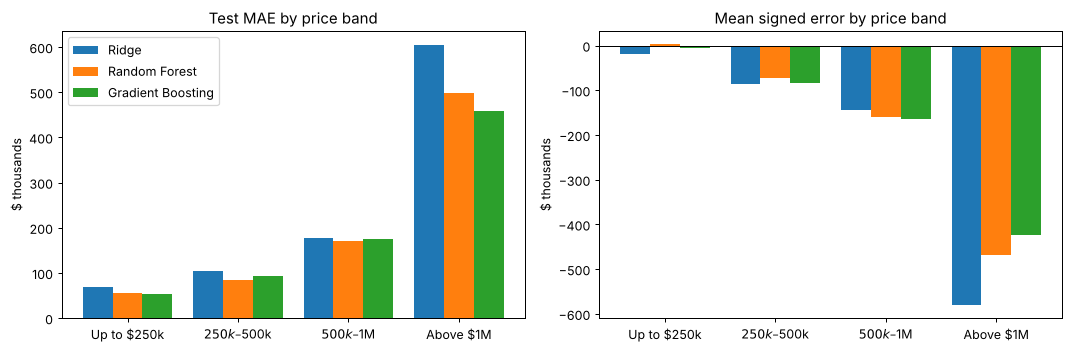

In [65]:
bands = ["Up to $250k", "$250k–$500k", "$500k–$1M", "Above $1M"]
model_bands = {"Ridge": ridge_band_results, "RF": rf_band_results, "GB": gb_band_results}

band_table = pd.DataFrame({"Price band": bands, "Records": ridge_band_results["records"].to_numpy()})
for m, b in model_bands.items():
    band_table[f"{m} MAE"] = b["MAE"].to_numpy()
for m, b in model_bands.items():
    band_table[f"{m} bias"] = b["mean_error"].to_numpy()

test_bands = pd.cut(y_test, bins=[0, 250_000, 500_000, 1_000_000, np.inf], labels=bands, include_lowest=True)
band_mean_price = y_test.groupby(test_bands, observed=True).mean().to_numpy()
for m in model_bands:
    band_table[f"{m} MAE % of price"] = band_table[f"{m} MAE"] / band_mean_price

display_table = band_table.copy()
for c in display_table.columns:
    if "%" in c:
        display_table[c] = display_table[c].map(lambda v: f"{v:.0%}")
    elif c not in ("Price band", "Records"):
        display_table[c] = display_table[c].map(lambda v: f"{v:,.0f}")
print(display_table.to_markdown(index=False))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
x = np.arange(len(bands)); w = 0.27
for i, (m, label) in enumerate([("Ridge", "Ridge"), ("RF", "Random Forest"), ("GB", "Gradient Boosting")]):
    axes[0].bar(x + (i - 1) * w, band_table[f"{m} MAE"] / 1000, w, label=label)
    axes[1].bar(x + (i - 1) * w, band_table[f"{m} bias"] / 1000, w, label=label)
for ax, title in [(axes[0], "Test MAE by price band"), (axes[1], "Mean signed error by price band")]:
    ax.set_xticks(x); ax.set_xticklabels(bands); ax.set_title(title); ax.set_ylabel("$ thousands")
axes[1].axhline(0, color="black", linewidth=0.8)
axes[0].legend()
plt.tight_layout(); plt.show()

In [66]:
# Price drift between periods and the overall direction of errors on the 2025 test set
price_drift = pd.DataFrame({
    "period": ["Training 2017–2023", "Validation 2024", "Test 2025"],
    "mean price": [y_train.mean(), y_val.mean(), y_test.mean()],
    "median price": [y_train.median(), y_val.median(), y_test.median()],
})
display(price_drift.round(0))

direction = pd.DataFrame([
    {"model": name, "share underpredicted": (e["error"] < 0).mean(), "median signed error": e["error"].median()}
    for name, e in [("Ridge", ridge_test_errors), ("Random Forest", rf_test_errors), ("Gradient Boosting", gb_test_errors)]
])
direction.round(3)

,period,mean price,median price
0,Training 2017–2023,350714.0,270000.0
1,Validation 2024,444157.0,339900.0
2,Test 2025,473135.0,353000.0


,model,share underpredicted,median signed error
0,Ridge,0.806,-89156.019
1,Random Forest,0.794,-73796.124
2,Gradient Boosting,0.814,-83941.360


### 8.3 Do Geographic Indicators Improve Performance?

We retrain Ridge and Gradient Boosting (both quick to fit) with their selected hyperparameters on four
input sets, keeping everything else fixed, and compare validation and test error:

| Input set | Inputs |
|---|---|
| **All shared inputs** | the 81 shared features |
| **No geographic identifiers** | drops coordinates and area codes: latitude, longitude, city, ZIP, municipality, elementary and secondary school district (74 inputs) |
| **Property only** | the 25 `char_*` features: no location or neighbourhood context at all |
| **+ Neighbourhood codes** | the 81 features plus the assessor's township and neighbourhood codes (83 inputs) |

Neighbourhood and township codes were not in the shared input set; they are assessor location codes
known before a sale. Random Forest is too slow to refit four
times, so for it we use the grouped permutation test from Section 6.7.

The "All shared inputs" rows are fresh refits, of the selected configurations; comparisons are always made within the same refit.

In [67]:
geo_identifiers = ["loc_latitude", "loc_longitude", "loc_property_city", "loc_property_zip",
                   "loc_tax_municipality_name", "loc_school_elementary_district_geoid",
                   "loc_school_secondary_district_geoid"]

def with_neighbourhood(X, source):
    out = X.copy()
    out["meta_township_code"] = source["meta_township_code"].astype(str).to_numpy()
    out["meta_nbhd_code"] = source["meta_nbhd_code"].astype(str).to_numpy()
    return out

def make_encoder(kind, numeric, categorical):
    if kind == "ridge":
        return ColumnTransformer([
            ("num", StandardScaler(), numeric),
            ("cat", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=20), categorical)])
    return ColumnTransformer([
        ("num", "passthrough", numeric),
        ("cat", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1), categorical)])

def make_model(kind):
    if kind == "ridge":
        return Ridge(alpha=best_alpha, solver="lsqr")
    return HistGradientBoostingRegressor(random_state=42, **gb_best_params)

input_sets = {
    "All shared inputs": (NUMERIC_FEATURES, CATEGORICAL_FEATURES, False),
    "No geographic identifiers": ([f for f in NUMERIC_FEATURES if f not in geo_identifiers],
                                  [f for f in CATEGORICAL_FEATURES if f not in geo_identifiers], False),
    "Property only": ([f for f in NUMERIC_FEATURES if f.startswith("char_")],
                      [f for f in CATEGORICAL_FEATURES if f.startswith("char_")], False),
    "+ Neighbourhood codes": (NUMERIC_FEATURES, CATEGORICAL_FEATURES + ["meta_township_code", "meta_nbhd_code"], True),
}

ablation_rows = []
for kind, label in [("ridge", "Ridge"), ("gb", "Gradient Boosting")]:
    for set_name, (num, cat, add_nbhd) in input_sets.items():
        Xtr_s, Xva_s, Xte_s = X_train, X_val, X_test
        if add_nbhd:
            Xtr_s, Xva_s, Xte_s = (with_neighbourhood(X_train, train_df), with_neighbourhood(X_val, val_df),
                                   with_neighbourhood(X_test, test_df))
        pipe = make_pipeline(make_encoder(kind, num, cat), make_model(kind)).fit(Xtr_s, y_train)
        for split, X, y in [("Validation 2024", Xva_s, y_val), ("Test 2025", Xte_s, y_test)]:
            r = evaluate_predictions(label, y, pipe.predict(X))
            r.update(input_set=set_name, n_inputs=len(num) + len(cat), split=split)
            ablation_rows.append(r)
        print(f"{label:<18} | {set_name:<26} | inputs={len(num) + len(cat):>2} | "
              f"val R²={ablation_rows[-2]['R2']:.4f} | test R²={ablation_rows[-1]['R2']:.4f}")

ablation = pd.DataFrame(ablation_rows)[["model", "input_set", "n_inputs", "split", "MAE", "RMSE", "R2"]]

Ridge              | All shared inputs          | inputs=81 | val R²=0.7147 | test R²=0.5815
Ridge              | No geographic identifiers  | inputs=74 | val R²=0.6135 | test R²=0.5035
Ridge              | Property only              | inputs=25 | val R²=0.5493 | test R²=0.4530
Ridge              | + Neighbourhood codes      | inputs=83 | val R²=0.7326 | test R²=0.6674
Gradient Boosting  | All shared inputs          | inputs=81 | val R²=0.8175 | test R²=0.7636
Gradient Boosting  | No geographic identifiers  | inputs=74 | val R²=0.8103 | test R²=0.7588
Gradient Boosting  | Property only              | inputs=25 | val R²=0.6563 | test R²=0.5576
Gradient Boosting  | + Neighbourhood codes      | inputs=83 | val R²=0.8151 | test R²=0.7676


In [68]:
# Change relative to "All shared inputs" for the same model and split
ref = ablation[ablation["input_set"] == "All shared inputs"].set_index(["model", "split"])
ablation["ΔRMSE vs all"] = ablation.apply(lambda r: r["RMSE"] - ref.loc[(r["model"], r["split"]), "RMSE"], axis=1)
ablation["ΔR² vs all"] = ablation.apply(lambda r: r["R2"] - ref.loc[(r["model"], r["split"]), "R2"], axis=1)

view = ablation.copy()
for c in ["MAE", "RMSE", "ΔRMSE vs all"]:
    view[c] = view[c].map(lambda v: f"{v:+,.0f}" if c.startswith("Δ") else f"{v:,.0f}")
for c in ["R2", "ΔR² vs all"]:
    view[c] = view[c].map(lambda v: f"{v:+.4f}" if c.startswith("Δ") else f"{v:.4f}")
print(view.to_markdown(index=False))

display(rf_group_importance.round(0))

| model             | input_set                 |   n_inputs | split           |     MAE |    RMSE |     R2 |   ΔRMSE vs all |   ΔR² vs all |
|:------------------|:--------------------------|-----------:|:----------------|--------:|--------:|-------:|---------------:|-------------:|
| Ridge             | All shared inputs         |         81 | Validation 2024 | 126,763 | 231,839 | 0.7147 |             +0 |       0      |
| Ridge             | All shared inputs         |         81 | Test 2025       | 147,295 | 348,120 | 0.5815 |             +0 |       0      |
| Ridge             | No geographic identifiers |         74 | Validation 2024 | 155,446 | 269,876 | 0.6135 |        +38,037 |      -0.1013 |
| Ridge             | No geographic identifiers |         74 | Test 2025       | 175,390 | 379,159 | 0.5035 |        +31,040 |      -0.078  |
| Ridge             | Property only             |         25 | Validation 2024 | 169,343 | 291,398 | 0.5493 |        +59,559 |      -0.1654 |
| Ridg

,feature group,features,RMSE increase when shuffled ($)
0,Property characteristics (char_*),25,198772.0
1,"Location & context (loc_*, prox_*, shp_*)",56,212573.0
2,"Coordinates only (latitude, longitude)",2,103701.0


### 8.4 Findings

**1. Model comparison.** All three models clearly beat the mean-price baseline. On 2025 sales,
Gradient Boosting has the best RMSE and R² (\$261,611, 0.764), Random Forest has the best MAE
(\$124,356, −50.1% vs baseline) and Ridge trails both (R² 0.581). The two tree ensembles are close:
Random Forest is slightly better on typical homes, Gradient Boosting on the largest errors.
All models lose accuracy from 2024 to 2025, and Ridge loses the most (R² 0.715 → 0.581).

**2. Where all models struggle.**
- **Expensive homes.** Every model underpredicts every band above \$250k, and the bias grows with price:
  above \$1M the mean error is −\$580k (Ridge), −\$469k (RF) and −\$424k (GB). In relative terms the tree
  models' MAE is 26–28% of the price above \$1M, against 35% for Ridge.
- **Cheap homes are hard in relative terms.** Below \$250k the bias is small (between −\$18k and +\$3k),
  but MAE is 34–44% of the average price, the highest relative error of any band.
- **Market drift.** Average prices rose from \$350,714 (2017–2023) to \$473,135 (2025). None of the models
  has a sale-date or price-index input, so they predict at roughly training-period price levels: about
  80% of 2025 sales are underpredicted by every model (Ridge 80.6%, RF 79.4%, GB 81.4%). This shift explains much of the
  drop from validation to test.
- **Negative prices.** Ridge produces 219 impossible negative predictions, Gradient Boosting one and Random Forest none
  (a forest can only predict averages of observed prices).

**3. Geographic indicators.**
- **Location information is essential.** With property characteristics only, validation R² falls by
  0.165 for Ridge and 0.161 for Gradient Boosting. In Random Forest, shuffling the location and context
  inputs raises validation RMSE more (\$212,573) than shuffling the property characteristics (\$198,772).
- **Explicit coordinates and area codes matter mainly for the linear model.** Removing the seven geographic
  identifiers costs Ridge 0.101 validation R², but Gradient Boosting only 0.007. The trees recover location
  from the remaining contextual inputs (e.g. distance to Lake Michigan, airport noise, walkability).
  In Random Forest, latitude and longitude alone still account for \$103,701 of validation RMSE when shuffled,
  so trees *use* coordinates heavily even if they can partly substitute for them.
- **Neighbourhood codes help Ridge, not the trees.** Adding the assessor's township and neighbourhood codes
  improves Ridge (validation RMSE −\$7,365, R² +0.018) because one-hot area codes give a linear model the local
  price levels it cannot build from coordinates. For Gradient Boosting the change is within noise
  (validation R² −0.002). These codes were not in the shared input set, so this is an exploratory result;
  the final models are unchanged.

## 9. Conclusion

### What we achieved
- A leakage-safe, reproducible pipeline: one set of eligibility rules, a chronological split
  (2017–2023 / 2024 / 2025) and imputation and encoding fitted on training data only, shared by all models.
- Three models tuned on the 2024 validation set and evaluated once on 2025 sales. Both tree ensembles roughly
  **halve the mean-baseline MAE** (Random Forest −50.1%, Gradient Boosting −49.2%) and explain about 75% of
  price variance (R² 0.744 and 0.764), well ahead of Ridge (R² 0.581).
- Clear evidence that non-linear models suit this problem: they capture location effects and interactions
  that Ridge needs explicit area codes to approximate, and they almost never predict negative prices (one test sale for Gradient Boosting, none for Random Forest).
- Location is as important as the house itself: removing all location and context inputs lowers R² by about 0.16.

### Limitations
- **Underprediction of expensive homes:** errors above \$1M are \$424k–\$580k on average for every model.
- **Market drift:** without a time or price-index input, all models predict at past price levels, so
  performance drops from 2024 to 2025 and most 2025 sales are underpredicted.
- **Squared-error training on a skewed target:** a few very expensive sales dominate RMSE.
- **Historical availability** of every contextual input is not verified, and repeat sales of the same
  property appear in both training and test periods, so results are a retrospective comparison rather
  than a validated real-time forecast.
- Hyperparameter searches were small (seven alphas for Ridge, three configurations for Gradient Boosting,
  a staged search for Random Forest).

### What we would do with more time
1. **Model log(price)** so errors are relative and expensive homes weigh less on the fit, then convert back to dollars.
2. **Add a time signal** (sale month or a county price index) so models can follow market trends, and test it
   with a rolling-origin validation.
3. **Use neighbourhood codes** (or target-encoded areas) as shared inputs, which helped Ridge in our ablation.
4. **Larger, joint hyperparameter searches** for the tree models, plus monotonic constraints (e.g. more
   living area never lowers the predicted price).
5. **Verify feature timing** with the assessor's data documentation before any real-world use.

## 10. Contributions

| Member | Contributions |
|---|---|
| **Yuming ZHAI** | Data exploration, eligibility rules and shared feature selection (Section 2); Ridge Regression training, tuning and analysis (Section 5); introduction and EDA slides. |
| **Sakura ADHIKARY** | Shared preprocessing pipeline and chronological split (Section 3); Random Forest training, tuning and variance analysis (Section 6); joint error analysis and geographic ablation (Section 8); assembly of this notebook. |
| **Vida Kayla BENSING** | Review of existing solutions, evaluation metrics and mean-price baseline (Sections 1 and 4); Gradient Boosting training, tuning and analysis (Section 7); model comparison and slide assembly. |

All members contributed to the joint error analysis, the conclusion and the presentation.

## Acknowledgement

Use of Generative Artificial Intelligence (ChatGPT, Google Gemini, and Claude ) to research Python function and libraries, assistance with code development and debugging, improve structure of the project as well as the markdown report, and combine notebooks from the group members.